# TP2 Deep Learning : Partie 1 : Classification MNIST avec un CNN

**Objectif :** construire un réseau de neurones convolutif (CNN) avec PyTorch pour reconnaître des chiffres manuscrits (0 à 9), en utilisant le GPU.

**Plan de la partie 1 :**
1. Préparation de l'environnement et des données
2. Définition de l'architecture CNN
3. Entraînement
4. Évaluation (Accuracy, F1-score, Loss, temps d'entraînement)
5. Faster R-CNN
6. Comparaison des deux modèles
7. Fine-tuning de VGG16 et AlexNet

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/allalifatimaezzahra/dl-lab2-poids/cnn_mnist.pth
/kaggle/input/datasets/allalifatimaezzahra/dl-lab2-poids/etat.pkl
/kaggle/input/datasets/allalifatimaezzahra/dl-lab2-poids/faster_rcnn_mnist.pth
/kaggle/input/datasets/hojjatk/mnist-dataset/t10k-images.idx3-ubyte
/kaggle/input/datasets/hojjatk/mnist-dataset/t10k-labels.idx1-ubyte
/kaggle/input/datasets/hojjatk/mnist-dataset/train-images.idx3-ubyte
/kaggle/input/datasets/hojjatk/mnist-dataset/train-labels.idx1-ubyte
/kaggle/input/datasets/hojjatk/mnist-dataset/t10k-images-idx3-ubyte/t10k-images-idx3-ubyte
/kaggle/input/datasets/hojjatk/mnist-dataset/t10k-labels-idx1-ubyte/t10k-labels-idx1-ubyte
/kaggle/input/datasets/hojjatk/mnist-dataset/train-images-idx3-ubyte/train-images-idx3-ubyte
/kaggle/input/datasets/hojjatk/mnist-dataset/train-labels-idx1-ubyte/train-labels-idx1-ubyte


* train-images.idx3-ubyte   → images d'entraînement
* train-labels.idx1-ubyte   → réponses (chiffres) d'entraînement
* t10k-images.idx3-ubyte    → images de test
* t10k-labels.idx1-ubyte    → réponses (chiffres) de test

### ✅ Importer les outils dont on a besoin et vérifier que le GPU est bien actif.

In [2]:
# --- imports ---

import struct                                 # pour lire les données binaires des fichiers MNIST
import time                                   # pour mesurer le temps d'entraînement plus tard
import matplotlib.pyplot as plt               # pour afficher des images et des courbes

import torch                                  
import torch.nn as nn                         
import torch.optim as optim                  
from torch.utils.data import TensorDataset, DataLoader  # pour organiser les données en batchs

# --- verifier  si on a un GPU ---
# "cuda" = le GPU de Nvidia. Sinon on utilise le "cpu" 
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Je travaille sur :", device)

# afficher le nom de GPU
if device.type == "cuda":
    print("Nom du GPU :", torch.cuda.get_device_name(0))

Je travaille sur : cuda
Nom du GPU : Tesla T4


## Étape 1 : Chargement des données MNIST

**Le format IDX :** les fichiers ne sont pas des images classiques mais des fichiers binaires.
- Fichier d'images : un en-tête de 16 octets (nombre magique, nombre d'images, hauteur, largeur) suivi des pixels (valeurs de 0 à 255).
- Fichier de labels : un en-tête de 8 octets (nombre magique, nombre de labels) suivi des labels (un chiffre de 0 à 9 par image).


In [3]:
# --- Le dossier où se trouvent les fichiers MNIST ---
data_dir = "/kaggle/input/datasets/hojjatk/mnist-dataset"

# --- Fonction pour lire un fichier d'IMAGES ---
def read_images(path):
    with open(path, "rb") as f:                              # "rb" = lire en mode binaire
        # Les 16 premiers octets : magic number, nombre d'images, hauteur, largeur
        # ">IIII" veut dire : 4 entiers, lus dans l'ordre "big-endian" (format du fichier)
        magic, n, rows, cols = struct.unpack(">IIII", f.read(16))
        # Le reste du fichier = tous les pixels, chacun entre 0 et 255 (uint8)
        data = np.frombuffer(f.read(), dtype=np.uint8)
    # on remets les pixels en forme : (nombre d'images, hauteur, largeur)
    return data.reshape(n, rows, cols)

# --- Fonction pour lire un fichier de LABELS ---
def read_labels(path):
    with open(path, "rb") as f:
        # Les 8 premiers octets : magic number et nombre de labels
        magic, n = struct.unpack(">II", f.read(8))
        # Le reste = un label (0 à 9) par image
        labels = np.frombuffer(f.read(), dtype=np.uint8)
    return labels

# chargger les 4 fichiers 
train_images = read_images(os.path.join(data_dir, "train-images.idx3-ubyte"))
train_labels = read_labels(os.path.join(data_dir, "train-labels.idx1-ubyte"))
test_images  = read_images(os.path.join(data_dir, "t10k-images.idx3-ubyte"))
test_labels  = read_labels(os.path.join(data_dir, "t10k-labels.idx1-ubyte"))

# on verifie les tailles 
print("Images train :", train_images.shape)  
print("Labels train :", train_labels.shape)   
print("Images test  :", test_images.shape)    
print("Labels test  :", test_labels.shape)   
print("Valeur min / max des pixels :", train_images.min(), "/", train_images.max()) 

Images train : (60000, 28, 28)
Labels train : (60000,)
Images test  : (10000, 28, 28)
Labels test  : (10000,)
Valeur min / max des pixels : 0 / 255


## Préparation des données pour PyTorch

Les images brutes ne peuvent pas être données directement au CNN. On applique 4 transformations.

### 1. Conversion en tenseurs 
On transforme les tableaux NumPy en tenseurs PyTorch .

### 2. Mise à l'échelle (pixels de [0, 255] vers [0, 1])
On ramène tous les pixels dans l'intervalle de 0 à 1, car des valeurs aussi grandes que 255, multipliées par les poids, donnent des résultats énormes dans les couches du réseau. Alors , les calculs deviennent instables et les gradients peuvent exploser.

### 3. Normalisation (standardisation)
On centre les données autour de 0 en utilisant les statistiques de MNIST.

### 4. Ajout d'une dimension de canal
On passe de la forme `[N, 28, 28]` à `[N, 1, 28, 28]`.
- **Pourquoi :** la couche `Conv2d` attend le format `[batch, canaux, hauteur, largeur]`. Une image couleur a 3 canaux (rouge, vert, bleu). MNIST est en niveaux de gris, donc il n'y a qu'**1 canal**, mais la dimension doit exister.


### 5. DataLoader (batchs de 64, avec mélange)
On découpe le dataset en petits paquets de 64 images, et on mélange l'ordre à chaque epoch.
- **Pourquoi (batchs) :** donner les 60 000 images d'un coup saturerait la mémoire du GPU. Avec des mini-batchs, on met à jour les poids plusieurs fois par epoch, ce qui accélère l'apprentissage. 
- **Pourquoi (mélange) :** si les images arrivent toujours dans le même ordre, le modèle peut apprendre cet ordre au lieu d'apprendre les chiffres, et les mises à jour des poids deviennent biaisées.

In [4]:
# Conversion en tenseurs décimaux et mise à l'échelle [0, 255] -> [0, 1] 
X_train = torch.tensor(train_images, dtype=torch.float32) / 255.0
X_test  = torch.tensor(test_images,  dtype=torch.float32) / 255.0

# --- Normalisation : on calcule la moyenne et l'écart-type sur le TRAIN uniquement ---
mean = X_train.mean().item()   # moyenne de tous les pixels d'entraînement (item() donne un nombre simple)
std  = X_train.std().item()    # écart-type de tous les pixels d'entraînement
print("Moyenne calculée :", round(mean, 4)) 
print("Écart-type calculé :", round(std, 4))  

# On applique les MÊMES valeurs au train et au test
X_train = (X_train - mean) / std
X_test  = (X_test  - mean) / std

#  Ajout de la dimension de canal : (N, 28, 28) -> (N, 1, 28, 28) 
X_train = X_train.unsqueeze(1)
X_test  = X_test.unsqueeze(1)

# --- Les labels doivent être de type "long" (entiers) pour CrossEntropyLoss 
y_train = torch.tensor(train_labels, dtype=torch.long)
y_test  = torch.tensor(test_labels,  dtype=torch.long)

# --- On regroupe images et labels ensemble ---
train_dataset = TensorDataset(X_train, y_train)
test_dataset  = TensorDataset(X_test, y_test)

# --- Création des DataLoader ---
batch_size = 64   # nombre d'images traitées en même temps

# shuffle=True : on mélange les images à chaque epoch pour que le modèle n'apprenne pas l'ordre
trainloader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
# Pour le test, pas besoin de mélanger
testloader  = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# --- Verification de la forme et de la normalisation ---
images, labels = next(iter(trainloader))
print("Forme d'un batch d'images :", images.shape)   
print("Forme d'un batch de labels :", labels.shape)   
print("Moyenne du train après normalisation :", round(X_train.mean().item(), 4)) 
print("Écart-type du train après normalisation :", round(X_train.std().item(), 4))  

Moyenne calculée : 0.1307
Écart-type calculé : 0.3081
Forme d'un batch d'images : torch.Size([64, 1, 28, 28])
Forme d'un batch de labels : torch.Size([64])
Moyenne du train après normalisation : -0.0
Écart-type du train après normalisation : 1.0


## Étape 2 : Architecture du CNN

Le réseau est composé de deux parties :
1. **Extraction des caractéristiques** (couches convolutives) : détectent les motifs dans l'image (bords, courbes, formes).
2. **Classification** (couches fully connected) : utilisent ces motifs pour décider quel chiffre est représenté.

| Hyperparamètre | Valeur | Rôle |
|---|---|---|
| Kernel size | 3×3 | Taille du filtre qui parcourt l'image |
| Padding | 0(défaut) | Pas de bordure ajoutée : l'image rétrécit de 2 pixels à chaque convolution|
| Stride | 1 (défaut) | Le filtre avance d'un pixel à la fois |
| Pooling | MaxPool 2×2 |  Divise la taille par 2 et garde les motifs les plus marqués |
| Activation | ReLU | Ajoute la non-linéarité |
| Dropout | 0.25 | Régularisation : évite le surapprentissage |

**Choix du padding** : on garde padding=0 (valeur par défaut). Les chiffres MNIST sont centrés avec des bords noirs, donc la perte d'information sur les bords est négligeable.

In [5]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()

        # n va faire : Conv → ReLU → Pool → Conv → ReLU → Pool → Flatten → FC 

        
        # --- Partie 1 : Feature selection ---
        self.features = nn.Sequential(
            # Bloc 1 : 1 canal en entrée, 16 filtres de taille 3x3, padding=0
            nn.Conv2d(1, 16, kernel_size=3, padding=0),   # (1,28,28) -> (16,26,26)
            nn.ReLU(),                                    # on garde seulement les valeurs positives
            nn.MaxPool2d(2),                              # (16,26,26) -> (16,13,13)

            # Bloc 2 : 16 canaux en entrée, 32 filtres de taille 3x3, padding=0
            nn.Conv2d(16, 32, kernel_size=3, padding=0),  # (16,13,13) -> (32,11,11)
            nn.ReLU(),
            nn.MaxPool2d(2),                              # (32,11,11) -> (32,5,5)
        )

        # --- Partie 2 : classification ---
        self.classifier = nn.Sequential(
            nn.Flatten(),                  # (32,5,5) -> vecteur de 32*5*5 = 800 valeurs
            nn.Linear(32 * 5 * 5, 128),    # 800 -> 128 neurones
            nn.ReLU(),          
            nn.Dropout(0.25),              # on éteint 25% des neurones au hasard (entraînement seulement)
            nn.Linear(128, 10),            # 128 -> 10 sorties (une par chiffre de 0 à 9)
        )

    # forward :
    def forward(self, x):
        x = self.features(x)       # d'abord on extrait les motifs
        x = self.classifier(x)     # ensuite on classe
        return x                   # 10 scores 

# On crée le modèle et on l'envoie sur le GPU
model = CNN().to(device)
print(model)

# --- Vérification : on passe un batch dans le modèle ---
test_batch = images.to(device)           # "images" vient de la cellule précédente
sortie = model(test_batch)
print("Forme de la sortie :", sortie.shape)  

# --- Nombre de parametres a apprendre ---
total = sum(p.numel() for p in model.parameters())
print("Nombre de paramètres :", total)

CNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=800, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.25, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Forme de la sortie : torch.Size([64, 10])
Nombre de paramètres : 108618


### Parcours d'une image dans le CNN

```
ENTRÉE : 1 image en niveaux de gris                      [1, 28, 28]
   │
   │  CONV 1 : 16 filtres 3×3 (padding=0)
   │    filtre 1  → carte 1  (26×26)   
   │    filtre 2  → carte 2  (26×26)   
   │    ...
   │    filtre 16 → carte 16 (26×26)
   ▼
16 cartes empilées                                       [16, 26, 26]
   │  ReLU : les valeurs négatives deviennent 0
   │  MaxPool 2×2 : chaque zone 2×2 est résumée par son maximum
   ▼
                                                         [16, 13, 13]
   │
   │  CONV 2 : 32 filtres 3×3 (chaque filtre regarde les 16 cartes à la fois)
   │    combine les traits simples pour détecter des formes (courbes, angles)
   ▼
32 cartes                                                [32, 11, 11]
   │  ReLU
   │  MaxPool 2×2
   ▼
                                                         [32, 5, 5]
   │
   │  FLATTEN : on met toutes les cartes à plat (32 × 5 × 5)
   ▼
Vecteur de 800 valeurs                                   [800]
   │
   │  LINEAR 800 → 128 : 128 neurones, chacun fait une somme pondérée des 800 valeurs
   │  ReLU + Dropout (0.25)
   ▼
                                                         [128]
   │
   │  LINEAR 128 → 10 : 1 neurone par chiffre (0 à 9)
   ▼
SORTIE : 10 scores (logits), le plus grand = chiffre prédit   [10]
```


## Étape 3 : Entraînement du modèle

| Élément | Choix | Rôle |
|---|---|---|
| Fonction de perte | CrossEntropyLoss | Mesure l'erreur entre les 10 scores et le vrai chiffre (applique le softmax en interne) |
| Optimiseur | Adam (lr = 0.001) | Ajuste les poids ; combine Momentum et RMSprop |
| Epochs | 5 | 	MNIST est simple, 5 passages complets suffisent  |
| Batch size | 64 | Nombre d'images vues avant chaque mise à jour des poids |

À chaque epoch, on mesure la loss et l'accuracy sur l'entraînement et sur le test, ainsi que le temps total d'entraînement (utile pour la comparaison finale).

In [6]:
def entrainer(model, trainloader, testloader, epochs=5, lr=0.001):
    # Loss
    criterion = nn.CrossEntropyLoss()
    # optimisation : Adam , lr = 0.001 ( lr = learning rate)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    # On garde l'historique pour tracer les courbes plus tard
    historique = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}

    # On attend que le GPU soit prêt, puis on démarre le chronomètre
    torch.cuda.synchronize()
    debut = time.time()

    for epoch in range(epochs):

        # ----- PHASE 1 : entraînement -----
        model.train()                      # mode entraînement (ici le droupout est est actif)
        perte_totale, bonnes, total = 0, 0, 0

        for images, labels in trainloader:
            images, labels = images.to(device), labels.to(device)   # on envoie les données sur le GPU

            optimizer.zero_grad()                  # effacer les anciens valeurs du gradient 
            sorties = model(images)                # forward
            loss = criterion(sorties, labels)      # calculer l'erreur
            loss.backward()                        # on calcule les gradients (backward)
            optimizer.step()                       # on met a jour les poids

            # On cumule la loss et le nombre de bonnes prédictions
            perte_totale += loss.item() * images.size(0)
            bonnes += (sorties.argmax(dim=1) == labels).sum().item()   # argmax = le score le plus grand
            total += images.size(0)

        train_loss = perte_totale / total # Loss d'une epoch
        train_acc = bonnes / total

        # ----- PHASE 2 : test (on ne modifie plus les poids) -----
        model.eval()                       # mode evaluation (le Dropout est désactivé)
        perte_totale, bonnes, total = 0, 0, 0

        with torch.no_grad():              # dit à PyTorch de ne pas calculer les gradients, parce qu’on ne va pas corriger de poids. 
            for images, labels in testloader:
                images, labels = images.to(device), labels.to(device)
                sorties = model(images)
                loss = criterion(sorties, labels)

                perte_totale += loss.item() * images.size(0)
                bonnes += (sorties.argmax(dim=1) == labels).sum().item()
                total += images.size(0)

        test_loss = perte_totale / total
        test_acc = bonnes / total

        # On enregistre les resultats de cette epoch
        historique["train_loss"].append(train_loss)
        historique["train_acc"].append(train_acc)
        historique["test_loss"].append(test_loss)
        historique["test_acc"].append(test_acc)

        print(f"Epoch {epoch+1}/{epochs} | "
              f"Train loss: {train_loss:.4f}, acc: {train_acc:.4f} | "
              f"Test loss: {test_loss:.4f}, acc: {test_acc:.4f}")

    # On arrete le chronomètre
    torch.cuda.synchronize()
    temps = time.time() - debut
    print(f"Temps d'entraînement : {temps:.1f} secondes")

    return historique, temps

In [23]:
# modèle CNN 
model = CNN().to(device)

# On lance l'entraînement
historique_cnn, temps_cnn = entrainer(model, trainloader, testloader, epochs=5, lr=0.001)

Epoch 1/5 | Train loss: 0.1995, acc: 0.9387 | Test loss: 0.0493, acc: 0.9848
Epoch 2/5 | Train loss: 0.0620, acc: 0.9807 | Test loss: 0.0377, acc: 0.9866
Epoch 3/5 | Train loss: 0.0455, acc: 0.9862 | Test loss: 0.0332, acc: 0.9899
Epoch 4/5 | Train loss: 0.0376, acc: 0.9877 | Test loss: 0.0344, acc: 0.9889
Epoch 5/5 | Train loss: 0.0306, acc: 0.9898 | Test loss: 0.0266, acc: 0.9911
Temps d'entraînement : 14.5 secondes


## Étape 4 : Évaluation du CNN

On évalue le modèle sur la partie  de test avec plusieurs métriques :
- **Accuracy** : pourcentage de bonnes prédictions
- **F1-score (macro)** : moyenne sur les 10 classes de la combinaison précision/rappel
- **Loss** : erreur mesurée par la CrossEntropy
- **Temps d'entraînement**

La matrice de confusion montre quels chiffres sont confondus entre eux.

**Les métriques**

In [24]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# On fixe la graine aléatoire pour que les résultats soient reproductibles
torch.manual_seed(42)
torch.backends.cudnn.deterministic = True   # le GPU utilise des calculs déterministes
torch.backends.cudnn.benchmark = False      # désactive le choix automatique d'algorithmes (qui peut varier)

# Cette fonction reupere les predictions du modèle sur tout le jeu de test
def predire(model, loader):
    model.eval()                                   # mode test (Dropout désactivé)
    toutes_preds, tous_labels = [], []
    with torch.no_grad():                          # pas de gradients, on ne fait que prédire
        for images, labels in loader:
            images = images.to(device)             # on envoie les images sur le GPU
            sorties = model(images)                # 10 scores par image
            preds = sorties.argmax(dim=1).cpu()    # le score le plus grand = le chiffre prédit
            toutes_preds.extend(preds.tolist())
            tous_labels.extend(labels.tolist())
    return np.array(tous_labels), np.array(toutes_preds)

# On récupère les vrais chiffres et les chiffres prédits
y_vrai, y_pred = predire(model, testloader)

# On calcule les métriques
acc = accuracy_score(y_vrai, y_pred)
f1 = f1_score(y_vrai, y_pred, average="macro")     # macro = moyenne des F1 des 10 classes
print(f"Accuracy : {acc:.4f}")
print(f"F1-score (macro) : {f1:.4f}")
print(f"Loss test (dernière epoch) : {historique_cnn['test_loss'][-1]:.4f}")
print(f"Temps d'entraînement : {temps_cnn:.1f} s")

#  précision, rappel et F1 de chaque classe
print(classification_report(y_vrai, y_pred, digits=4))

# On garde les resultats du CNN dans un dictionnaire pour la comparaison finale
resultats = {}
resultats["CNN"] = {
    "accuracy": acc,
    "f1": f1,
    "loss": historique_cnn["test_loss"][-1],
    "temps": temps_cnn,
}

Accuracy : 0.9911
F1-score (macro) : 0.9911
Loss test (dernière epoch) : 0.0266
Temps d'entraînement : 14.5 s
              precision    recall  f1-score   support

           0     0.9928    0.9918    0.9923       980
           1     0.9886    0.9965    0.9925      1135
           2     0.9971    0.9874    0.9922      1032
           3     0.9892    0.9950    0.9921      1010
           4     0.9929    0.9949    0.9939       982
           5     0.9866    0.9888    0.9877       892
           6     0.9917    0.9937    0.9927       958
           7     0.9922    0.9883    0.9903      1028
           8     0.9938    0.9877    0.9907       974
           9     0.9861    0.9861    0.9861      1009

    accuracy                         0.9911     10000
   macro avg     0.9911    0.9910    0.9911     10000
weighted avg     0.9911    0.9911    0.9911     10000



**Matrice de confusion**

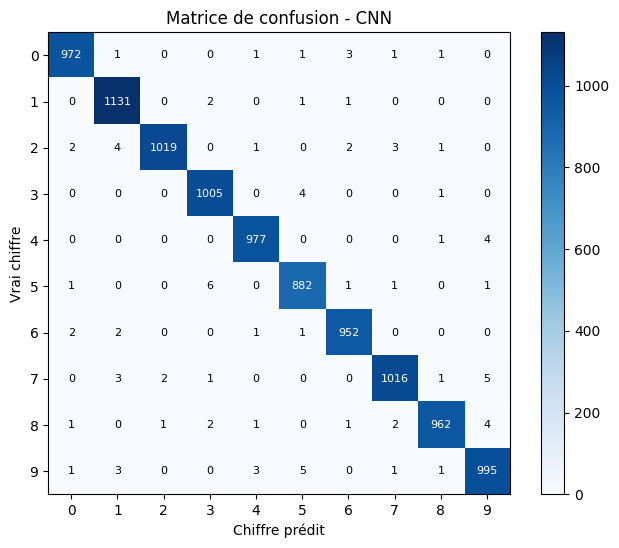

In [25]:
# La matrice de confusion : ligne = vrai chiffre, colonne = chiffre prédit
cm = confusion_matrix(y_vrai, y_pred)

plt.figure(figsize=(8, 6))
plt.imshow(cm, cmap="Blues")
plt.title("Matrice de confusion - CNN")
plt.xlabel("Chiffre prédit")
plt.ylabel("Vrai chiffre")
plt.xticks(range(10))
plt.yticks(range(10))
plt.colorbar()

# On écrit le nombre dans chaque case
for i in range(10):
    for j in range(10):
        couleur = "white" if cm[i, j] > cm.max() / 2 else "black"
        plt.text(j, i, cm[i, j], ha="center", va="center", color=couleur, fontsize=8)

plt.show()

**Courbes d’apprentissage**

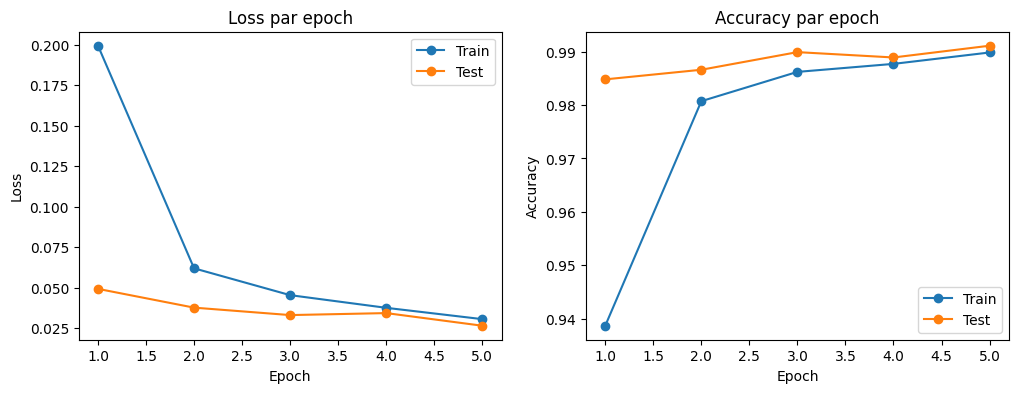

In [26]:
epochs_x = range(1, len(historique_cnn["train_loss"]) + 1)

plt.figure(figsize=(12, 4))

# Courbe de la loss
plt.subplot(1, 2, 1)
plt.plot(epochs_x, historique_cnn["train_loss"], marker="o", label="Train")
plt.plot(epochs_x, historique_cnn["test_loss"], marker="o", label="Test")
plt.title("Loss par epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

# Courbe de l'accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs_x, historique_cnn["train_acc"], marker="o", label="Train")
plt.plot(epochs_x, historique_cnn["test_acc"], marker="o", label="Test")
plt.title("Accuracy par epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

### Interprétation des résultats du CNN

| Métrique | Valeur |
|---|---|
| Accuracy (test) | 0.9911 |
| F1-score (macro) | 0.9911 |
| Loss (test) | 0.0266 |
| Temps d'entraînement (GPU) | 14.5 s |

**Performance globale** : le CNN classe correctement 9 911 images sur 10 000, soit seulement 89 erreurs. L'accuracy et le F1-score sont identiques (0.9911) parce que les 10 classes de MNIST sont presque équilibrées et que le modèle se comporte de la même façon sur toutes.

**Analyse par chiffre** : les chiffres 4 (F1 = 0.9939), 6 (0.9927) et 1 (0.9925) sont les mieux reconnus, car leur forme est simple et distincte. Les plus difficiles sont le 9 (0.9861) et le 5 (0.9877). Le 9 a la précision la plus faible (0.9861) et aussi le rappel le plus faible (0.9861) : le modèle manque certains vrais 9, et il prédit aussi « 9 » à tort pour d'autres chiffres.

**Matrice de confusion** : toutes les valeurs importantes sont sur la diagonale. Les erreurs les plus fréquentes concernent des chiffres de forme proche : 5 pris pour 3 (6 fois), 7 pris pour 9 et 9 pris pour 5 (5 fois chacun), 4 pris pour 9 (4 fois). Ces confusions sont normales, car l'écriture manuscrite de ces chiffres peut être très similaire. Ces erreurs précises varient légèrement d'une exécution à l'autre : ce sont des tendances, pas des règles.

**Courbes d'apprentissage** : la loss diminue et l'accuracy augmente à chaque epoch. Les courbes d'entraînement et de test se rejoignent à la fin, donc il n'y a pas de surapprentissage : le Dropout (0.25) remplit bien son rôle de régularisation. La loss de test est plus basse que celle d'entraînement au début, car la loss d'entraînement est une moyenne calculée pendant que le modèle apprend, et le Dropout n'est actif qu'à l'entraînement.

**Reproductibilité** : la graine aléatoire est fixée (`torch.manual_seed(42)`), donc ces résultats sont reproductibles. Le temps d'entraînement peut varier légèrement selon l'état du GPU.

## Étape 5 : Faster R-CNN

Faster R-CNN est un modèle de **détection d'objets** : il prédit pour chaque objet une boîte, une classe et un score de confiance. Il est composé de :
1. un **backbone** (un CNN) qui extrait les caractéristiques de l'image,
2. un **RPN** (Region Proposal Network) qui propose des régions où un objet pourrait se trouver,
3. une **tête de classification** qui donne la classe de chaque région et ajuste sa boîte.

### 5.1 Préparation des données

#### Qu'est-ce qu'une boîte (bounding box) ?

Une boîte est un **rectangle qui entoure un objet** dans l'image. Elle est décrite par 4 nombres :

- **Pendant l'entraînement** : elles indiquent au modèle où se trouve l'objet. C'est grâce à elles qu'il apprend à localiser.
- **Pendant la prédiction** : le modèle en produit lui-même, pour dire « l'objet est ici ».

**Différence avec le CNN :** le CNN répondait seulement « c'est un 7 ». Faster R-CNN répond « c'est un 7, et il se trouve dans ce rectangle ».

####  MNIST ne contient pas de boîtes

MNIST fournit seulement l'image et le chiffre (« cette image est un 7 »), sans aucune position. Or Faster R-CNN a besoin d'une boîte pour chaque image afin de s'entraîner.

**Solution : on les fabrique nous-mêmes.** Le chiffre est blanc sur fond noir, donc sa boîte est le plus petit rectangle qui contient tous les pixels allumés : on cherche la première et la dernière ligne, puis la première et la dernière colonne qui contiennent un pixel allumé.

#### Décalage des classes 
Les étiquettes sont décalées de 1 (chiffre 0 → classe 1, ..., chiffre 9 → classe 10), car la classe 0 est réservée au fond (background)



**💡Fabriquation des boîtes**

In [7]:
from torchvision import datasets, transforms
import matplotlib.patches as patches

# Ce Dataset reprend MNIST et ajoute à chaque image sa boîte englobante
class MNISTDetection(torch.utils.data.Dataset):
    def __init__(self, train=True):
        # On charge MNIST : valeurs entre 0 et 1, sans normalisation
        self.mnist = datasets.MNIST(root="./data", train=train, download=True,
                                    transform=transforms.ToTensor())

    def __len__(self):
        return len(self.mnist)

    def __getitem__(self, idx):
        image, chiffre = self.mnist[idx]          # image : [1, 28, 28], chiffre : 0 à 9

        # On repère les pixels "allumés" cad les pixels blancs)
        masque = image[0] > 0.2                   # tableau 28x28 de True/False

        # Lignes et colonnes qui contiennent au moins un pixel allumé
        lignes = torch.where(masque.any(dim=1))[0]
        colonnes = torch.where(masque.any(dim=0))[0]

        # La boîte : coin haut-gauche (x_min, y_min) et coin bas-droit (x_max, y_max)
        x_min, x_max = colonnes.min().item(), colonnes.max().item() + 1
        y_min, y_max = lignes.min().item(), lignes.max().item() + 1
        boite = torch.tensor([[x_min, y_min, x_max, y_max]], dtype=torch.float32)

        # La cible : une boîte et une classe (chiffre + 1, car 0 est réservé au fond)
        cible = {
            "boxes": boite,
            "labels": torch.tensor([chiffre + 1], dtype=torch.int64),
        }

        # Puisque Le modele attend 3 canaux (RGB)=>  on répète le canal gris 3 fois 
        image = image.repeat(3, 1, 1)             # [1,28,28] -> [3,28,28]

        return image, cible

# On crée les jeux d'entraînement et de test
data_det_train = MNISTDetection(train=True)
data_det_test = MNISTDetection(train=False)
print("Images d'entraînement :", len(data_det_train))
print("Images de test :", len(data_det_test))

# On regarde un exemple
image, cible = data_det_train[0]
print("Forme de l'image :", image.shape)    
print("Cible :", cible)

Images d'entraînement : 60000
Images de test : 10000
Forme de l'image : torch.Size([3, 28, 28])
Cible : {'boxes': tensor([[ 4.,  5., 24., 25.]]), 'labels': tensor([6])}


**💡 Vérification visuelle**

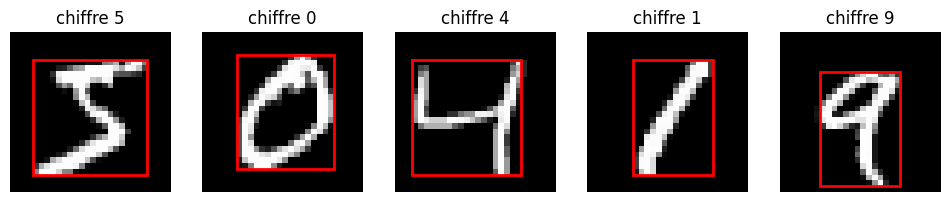

In [8]:
# On affiche 5 images avec leur boîte pour vérifier qu'elle entoure bien le chiffre
fig, axes = plt.subplots(1, 5, figsize=(12, 3))

for i, ax in enumerate(axes):
    image, cible = data_det_train[i]
    ax.imshow(image[0], cmap="gray")

    # On dessine la boîte en rouge (le -0.5 aligne le rectangle sur les bords des pixels)
    x1, y1, x2, y2 = cible["boxes"][0].tolist()
    ax.add_patch(patches.Rectangle((x1 - 0.5, y1 - 0.5), x2 - x1, y2 - y1,
                                   fill=False, edgecolor="red", linewidth=2))

    ax.set_title(f"chiffre {cible['labels'].item() - 1}")   # on retire le +1 pour afficher le vrai chiffre
    ax.axis("off")

plt.show()

### 5.2 Construction du modèle

On utilise le Faster R-CNN de `torchvision` (backbone **ResNet50 + FPN**) avec les réglages suivants :

| Hyperparamètre | Valeur | Rôle |
|---|---|---|
| Backbone | ResNet50 + FPN, poids ImageNet | CNN profond qui extrait les caractéristiques ; poids pré-entraînés pour apprendre plus vite |
| `num_classes` | 11 | 10 chiffres + 1 classe « fond » |
| `min_size` / `max_size` | 128 | Les images 28×28 sont redimensionnées en 128×128 en interne (800 par défaut, trop lent) |

**Fonctionnement** : le backbone produit des cartes de caractéristiques, le RPN propose des régions (à partir de boîtes de départ appelées *anchors*), le RoI pooling ramène chaque région à une taille fixe, puis les têtes prédisent la classe et corrigent la boîte.

**Loss** : en entraînement, le modèle renvoie 4 losses (`loss_classifier`, `loss_box_reg`, `loss_objectness`, `loss_rpn_box_reg`) que l'on additionne. En test, il renvoie directement des boîtes, des classes et des scores de confiance.

### 5.2 Faster R-CNN : présentation et construction du modèle

#### Ce qui diffère de notre CNN

| | CNN (étapes 1 à 4) | Faster R-CNN |
|---|---|---|
| **Tâche** | Classification : quel chiffre ? | Détection : quel chiffre **et où** ? |
| **Données** | Une image + un chiffre | Une image + une **boîte** + une classe |
| **Classes** | 10 | **11** (10 chiffres + le fond) |
| **Format d'entrée** | Un batch de tenseurs `[64,1,28,28]` | Une **liste** d'images 3 canaux + une liste de dictionnaires (boîtes, étiquettes) |
| **Normalisation** | Faite par nous (0.1307 / 0.3081) | Faite **par le modèle** : on donne des images brutes entre 0 et 1 |
| **Taille d'image** | 28×28 | Redimensionnée en interne (ici 128×128) |
| **Architecture** | Écrite par nous, couche par couche | Modèle `torchvision` déjà construit, dont on règle les hyperparamètres |
| **Taille du modèle** | 108 618 paramètres | Environ 41 millions |
| **Loss** | Une seule (CrossEntropy) | **4 losses** additionnées |
| **Sortie** | 10 scores | Des boîtes + classes + scores |
| **Prédiction finale** | `argmax` des 10 scores | La classe de la boîte au **meilleur score** |
| **Départ** | Poids aléatoires | Backbone **pré-entraîné** (ImageNet) |

 **💡Backbone** : C'est le CNN qui regarde l'image et extrait les motifs, comme nos couches Conv + ReLU + Pool, mais beaucoup plus profond (ResNet50 : 50 couches) |

#### Construction du modèle

| Hyperparamètre | Valeur | Rôle |
|---|---|---|
| Backbone | ResNet50 + FPN, poids ImageNet | CNN profond ; les poids pré-entraînés permettent d'apprendre beaucoup plus vite qu'en partant de zéro |
| `num_classes` | 11 | 10 chiffres + 1 classe « fond » |
| `min_size` / `max_size` | 128 | Les images 28×28 sont redimensionnées en 128×128 en interne (au lieu de 800 par défaut) |

**Les 4 losses** (renvoyées par le modèle en mode entraînement, puis additionnées) :
- `loss_classifier` : erreur sur la classe de la boîte finale
- `loss_box_reg` : erreur sur la position de la boîte finale
- `loss_objectness` : erreur du RPN sur « objet ou fond ? »
- `loss_rpn_box_reg` : erreur du RPN sur la position des boîtes proposées


In [9]:
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models import ResNet50_Weights

# On crée le Faster R-CNN :
# weights_backbone : le backbone ResNet50 est déjà entraîné sur ImageNet (il sait reconnaître des formes)
# num_classes=11 : 10 chiffres + 1 classe "fond"
# min_size / max_size = 128 : on redimensionne les images à 128x128 (au lieu de 800 par défaut)
model_rcnn = fasterrcnn_resnet50_fpn(
    weights=None,
    weights_backbone=ResNet50_Weights.IMAGENET1K_V1,
    num_classes=11,
    min_size=128,
    max_size=128,
)

# On envoie le modele sur le GPU
model_rcnn = model_rcnn.to(device)

# On compte les paramètres (pour comparer avec les 108 618 de notre CNN)
total = sum(p.numel() for p in model_rcnn.parameters())
print("Nombre de paramètres :", total)

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 190MB/s]


Nombre de paramètres : 41345286


In [10]:
# On prend 4 images avec leurs cibles, et on les envoie sur le GPU
images_test = []
cibles_test = []
for i in range(4):
    image, cible = data_det_train[i]
    images_test.append(image.to(device))
    cibles_test.append({"boxes": cible["boxes"].to(device), "labels": cible["labels"].to(device)})

# --- Mode entraînement : le modèle renvoie les 4 losses ---
model_rcnn.train()
losses = model_rcnn(images_test, cibles_test)
print("Losses en mode entraînement :")
for nom, valeur in losses.items():
    print(f"  {nom} : {valeur.item():.4f}")

# --- Mode test : le modèle renvoie des prédictions ---
model_rcnn.eval()
with torch.no_grad():
    predictions = model_rcnn(images_test)

print("\nPrédiction pour la 1ère image (modèle pas encore entraîné) :")
print("  Nombre de boîtes prédites :", len(predictions[0]["boxes"]))
print("  Clés du dictionnaire :", list(predictions[0].keys()))

Losses en mode entraînement :
  loss_classifier : 2.3992
  loss_box_reg : 0.1001
  loss_objectness : 0.6835
  loss_rpn_box_reg : 0.0157

Prédiction pour la 1ère image (modèle pas encore entraîné) :
  Nombre de boîtes prédites : 100
  Clés du dictionnaire : ['boxes', 'labels', 'scores']


### 5.3 Entraînement de Faster R-CNN

| Élément | Choix | Rôle |
|---|---|---|
| Données d'entraînement | 60 000 images | Les mêmes que pour le CNN, pour une comparaison équitable |
| Batch size | 16 | Nombre d'images vues avant chaque mise à jour des poids |
| Optimiseur | SGD (lr = 0.005, momentum = 0.9) | Ajuste les poids ; le momentum lisse les mises à jour |
| Régularisation | Weight decay = 0.0005 | Pénalise les poids trop grands pour limiter le surapprentissage |
| Epochs | 3 | Nombre de passages complets sur les 60 000 images |
| Loss | Somme des 4 losses du modèle | Classification, boîte, et les deux losses du RPN |

**Différences avec l'entraînement du CNN** :
- Les images et les cibles sont des **listes** (et non des tenseurs empilés) : on utilise un `collate_fn` dans le DataLoader.
- On appelle `model(images, cibles)` : le modèle renvoie lui-même un dictionnaire de 4 losses, que l'on additionne.
- Seules les couches non gelées du backbone sont entraînées (les premières couches pré-entraînées de ResNet50 sont conservées telles quelles).



In [27]:
# Les images et les cibles sont des listes : on regroupe les exemples sans les empiler
def collate(batch):
    return tuple(zip(*batch))    

# DataLoader d'entraînement :  par batch de 16, mélangées a chaque epoch
train_loader_det = DataLoader(data_det_train, batch_size=16, shuffle=True, collate_fn=collate)

# DataLoader de test 
test_loader_det = DataLoader(data_det_test, batch_size=64, shuffle=False, collate_fn=collate)

print("Images d'entraînement :", len(data_det_train))
print("Batchs par epoch :", len(train_loader_det))     

# On regarde un batch pour vérifier le format
images_b, cibles_b = next(iter(train_loader_det))
print("Type d'un batch d'images :", type(images_b), "| nombre d'images :", len(images_b))
print("Forme de la 1ère image :", images_b[0].shape)

Images d'entraînement : 60000
Batchs par epoch : 3750
Type d'un batch d'images : <class 'tuple'> | nombre d'images : 16
Forme de la 1ère image : torch.Size([3, 28, 28])


In [28]:

# On ne donne a l'optimiseur que les paramètres a entrainer (les premieres couches du backbone sont gelees)
params = [p for p in model_rcnn.parameters() if p.requires_grad]
optimizer = torch.optim.SGD(params, lr=0.005, momentum=0.9, weight_decay=0.0005)

EPOCHS = 3
historique_rcnn = {"loss_totale": []}

# On attend que le GPU soit pret, puis on demarre le chronometre
torch.cuda.synchronize()
debut = time.time()

for epoch in range(EPOCHS):
    model_rcnn.train()                       # mode entrainement
    perte_epoch = 0
    detail = {}                              # pour cumuler chacune des 4 losses

    for i, (images, cibles) in enumerate(train_loader_det):
        # On envoie les images et les cibles sur le GPU
        images = [img.to(device) for img in images]
        cibles = [{k: v.to(device) for k, v in c.items()} for c in cibles]

        pertes = model_rcnn(images, cibles)  # le modele renvoie un dictionnaire de 4 losses
        loss = sum(pertes.values())          # on additionne les 4 losses

        optimizer.zero_grad()                # effacer les anciens gradients
        loss.backward()                      # on calcule les gradients
        optimizer.step()                     # on met a jour les poids

        # On cumule les resultats pour l'affichage
        perte_epoch += loss.item()
        for nom, valeur in pertes.items():
            detail[nom] = detail.get(nom, 0) + valeur.item()

        # On affiche  tous les 500 batchs
        if (i + 1) % 500 == 0:
            print(f"  Epoch {epoch+1} - batch {i+1}/{len(train_loader_det)} - loss moyenne : {perte_epoch/(i+1):.4f}")

    # Moyenne sur l'epoch 
    n = len(train_loader_det)
    historique_rcnn["loss_totale"].append(perte_epoch / n)
    print(f"Epoch {epoch+1}/{EPOCHS} | Loss totale : {perte_epoch/n:.4f}")
    for nom, valeur in detail.items():
        print(f"    {nom} : {valeur/n:.4f}")

    # On sauvegarde les poids e la fin de chaque epoch 
    torch.save(model_rcnn.state_dict(), "faster_rcnn_mnist.pth")

torch.cuda.synchronize()
temps_rcnn = time.time() - debut
print(f"Temps d'entraînement : {temps_rcnn:.1f} secondes ({temps_rcnn/60:.1f} minutes)")

  Epoch 1 - batch 500/3750 - loss moyenne : 0.2405
  Epoch 1 - batch 1000/3750 - loss moyenne : 0.1689
  Epoch 1 - batch 1500/3750 - loss moyenne : 0.1335
  Epoch 1 - batch 2000/3750 - loss moyenne : 0.1116
  Epoch 1 - batch 2500/3750 - loss moyenne : 0.0971
  Epoch 1 - batch 3000/3750 - loss moyenne : 0.0869
  Epoch 1 - batch 3500/3750 - loss moyenne : 0.0792
Epoch 1/3 | Loss totale : 0.0759
    loss_classifier : 0.0412
    loss_box_reg : 0.0310
    loss_objectness : 0.0027
    loss_rpn_box_reg : 0.0010
  Epoch 2 - batch 500/3750 - loss moyenne : 0.0283
  Epoch 2 - batch 1000/3750 - loss moyenne : 0.0275
  Epoch 2 - batch 1500/3750 - loss moyenne : 0.0266
  Epoch 2 - batch 2000/3750 - loss moyenne : 0.0261
  Epoch 2 - batch 2500/3750 - loss moyenne : 0.0256
  Epoch 2 - batch 3000/3750 - loss moyenne : 0.0253
  Epoch 2 - batch 3500/3750 - loss moyenne : 0.0247
Epoch 2/3 | Loss totale : 0.0244
    loss_classifier : 0.0123
    loss_box_reg : 0.0117
    loss_objectness : 0.0002
    loss_r

### Interprétation de l'entraînement de Faster R-CNN

| Epoch | Loss totale | loss_classifier | loss_box_reg | loss_objectness | loss_rpn_box_reg |
|---|---|---|---|---|---|
| 1 | 0.0759 | 0.0412 | 0.0310 | 0.0027 | 0.0010 |
| 2 | 0.0244 | 0.0123 | 0.0117 | 0.0002 | 0.0003 |
| 3 | 0.0190 | 0.0098 | 0.0088 | 0.0001 | 0.0002 |

Temps d'entraînement : **5176 s (environ 86.3 minutes)** sur les 60 000 images, 3 epochs.

**Apprentissage très rapide** :On remarque que la loss totale passe de 0.0759 à 0.0190. La moyenne de la première epoch est surtout tirée vers le haut par les tout premiers batchs : au batch 500 de l'epoch 2, la moyenne est déjà à 0.0283, ce qui montre que le modèle a appris l'essentiel pendant la première epoch. Le backbone pré-entraîné (ImageNet) y contribue beaucoup.

**Convergence** : le gain devient faible entre l'epoch 2 (0.0244) et l'epoch 3 (0.0190), et la moyenne se stabilise à l'intérieur de l'epoch 3 (de 0.0203 à 0.0190). Le modèle a presque fini d'apprendre, et des epochs supplémentaires apporteraient peu.

**Détail des 4 losses** :
- Les losses du **RPN** (`loss_objectness` et `loss_rpn_box_reg`) tombent presque à zéro : repérer où se trouve le chiffre est facile, puisqu'il est seul, centré et blanc sur fond noir.
- La loss restante est répartie à peu près à égalité entre la **classification** (quel chiffre ?, 0.0098) et la **régression de la boîte** (position précise du rectangle, 0.0088).

**Temps** : On a environ 86.3 minutes, contre environ 15 secondes pour le CNN. => Faster R-CNN est bien plus lourd .

**Limite** : ces valeurs sont des losses d'**entraînement**. Elles ne disent pas encore si le modèle généralise bien : c'est l'évaluation sur les images de test  qui le dira.

### 5.4 Évaluation de Faster R-CNN

Faster R-CNN renvoie des boîtes, pas un chiffre. Pour comparer avec le CNN, on utilise la règle suivante pour chaque image de test :
- on garde la **boîte avec le meilleur score de confiance** ;
- le chiffre prédit est la classe de cette boîte moins 1 (rappel : le chiffre 0 correspond à la classe 1) ;
- si le modèle ne détecte **aucune boîte**, l'image est comptée comme une erreur.

Les métriques sont calculées sur les  images de test que pour le CNN : **accuracy**, **F1-score (macro)**, **loss** et **temps**. La loss de Faster R-CNN est la somme de ses 4 losses (  elle n'est pas directement comparable à la CrossEntropy du CNN. )

**💡prédictions et métriques**

In [29]:


#  les prédictions du modele sur  test part  ---
model_rcnn.eval()                              # mode evaluation 
y_vrai, y_pred = [], []

torch.cuda.synchronize()
debut = time.time()

with torch.no_grad():                          # pas de gradients, on ne fait que prédire
    for images, cibles in test_loader_det:
        images = [img.to(device) for img in images]
        predictions = model_rcnn(images)       # une liste de dictionnaires (boîtes, classes, scores)

        for pred, cible in zip(predictions, cibles):
            y_vrai.append(cible["labels"].item() - 1)       # vrai chiffre = classe - 1
            if len(pred["scores"]) == 0:
                y_pred.append(-1)                           # si aucune boite détectée => erreur ( image comptée comme une erreur)
            else:
                meilleur = pred["scores"].argmax()          # la boite avec le meilleur score
                y_pred.append(pred["labels"][meilleur].item() - 1)

torch.cuda.synchronize()
temps_inference = time.time() - debut

y_vrai = np.array(y_vrai)
y_pred = np.array(y_pred)

# Loss (somme des 4 losses) 
model_rcnn.train()                             # Car le modele ne renvoie ses losses qu'en mode train
loss_totale, n_batchs = 0, 0
with torch.no_grad():                          # aucun poids n'est modifie 
    for images, cibles in test_loader_det:
        images = [img.to(device) for img in images]
        cibles = [{k: v.to(device) for k, v in c.items()} for c in cibles]
        pertes = model_rcnn(images, cibles)
        loss_totale += sum(pertes.values()).item()
        n_batchs += 1
model_rcnn.eval()                              # on remet le mode evaluation
loss_test_rcnn = loss_totale / n_batchs

# Les métriques 
acc = accuracy_score(y_vrai, y_pred)
# labels=range(10) : une image sans boîte (-1) compte comme un chiffre raté
f1 = f1_score(y_vrai, y_pred, labels=list(range(10)), average="macro")

print(f"Accuracy : {acc:.4f}")
print(f"F1-score (macro) : {f1:.4f}")
print(f"Loss test (somme des 4 losses) : {loss_test_rcnn:.4f}")
print(f"Temps d'entraînement : {temps_rcnn/60:.1f} minutes")
print(f"Temps d'inférence sur 10 000 images : {temps_inference:.1f} secondes")
print(f"Images sans aucune détection : {(y_pred == -1).sum()}")

# Detail par chiffre
print(classification_report(y_vrai, y_pred, labels=list(range(10)), digits=4))

# On garde les resultats pour la comparaison finale
resultats["Faster R-CNN"] = {
    "accuracy": acc,
    "f1": f1,
    "loss": loss_test_rcnn,
    "temps": temps_rcnn,
    "temps_inference": temps_inference,
}

Accuracy : 0.9901
F1-score (macro) : 0.9900
Loss test (somme des 4 losses) : 0.0172
Temps d'entraînement : 86.3 minutes
Temps d'inférence sur 10 000 images : 118.6 secondes
Images sans aucune détection : 0
              precision    recall  f1-score   support

           0     0.9848    0.9908    0.9878       980
           1     0.9965    0.9965    0.9965      1135
           2     0.9855    0.9913    0.9884      1032
           3     0.9931    0.9941    0.9936      1010
           4     0.9949    0.9868    0.9908       982
           5     0.9966    0.9854    0.9910       892
           6     0.9885    0.9875    0.9880       958
           7     0.9922    0.9903    0.9912      1028
           8     0.9768    0.9959    0.9863       974
           9     0.9920    0.9812    0.9865      1009

    accuracy                         0.9901     10000
   macro avg     0.9901    0.9900    0.9900     10000
weighted avg     0.9901    0.9901    0.9901     10000



**💡Matrice de confusion**

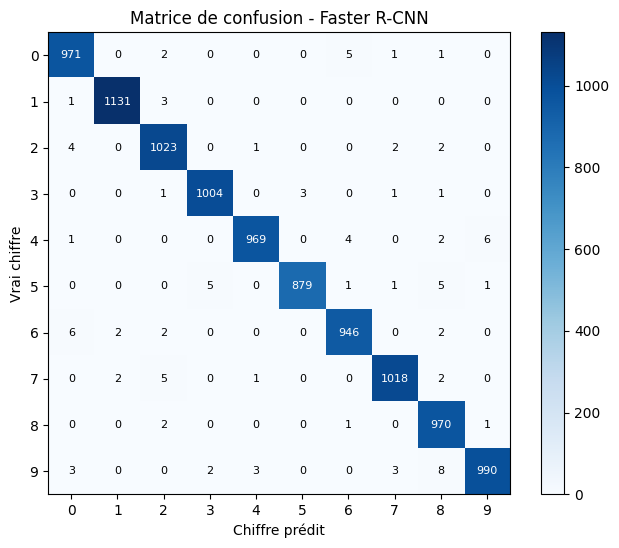

In [30]:

# Matrice de confusion : ligne = vrai chiffre, colonne = chiffre prédit
# Pour les images sans détection ne figurent pas dans la matrice
cm = confusion_matrix(y_vrai, y_pred, labels=list(range(10)))

plt.figure(figsize=(8, 6))
plt.imshow(cm, cmap="Blues")
plt.title("Matrice de confusion - Faster R-CNN")
plt.xlabel("Chiffre prédit")
plt.ylabel("Vrai chiffre")
plt.xticks(range(10))
plt.yticks(range(10))
plt.colorbar()

# On écrit le nombre dans chaque case
for i in range(10):
    for j in range(10):
        couleur = "white" if cm[i, j] > cm.max() / 2 else "black"
        plt.text(j, i, cm[i, j], ha="center", va="center", color=couleur, fontsize=8)

plt.show()

**💡 Vérification visuelle**

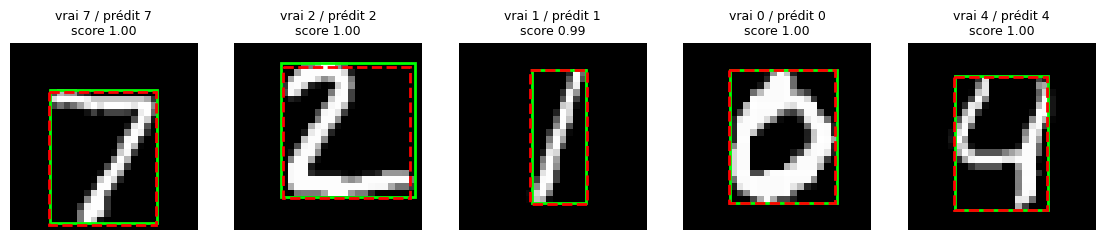

In [31]:

# On prend 5 images de test, et on affiche la boîte vraie (verte) et la boîte prédite (rouge)
model_rcnn.eval()
fig, axes = plt.subplots(1, 5, figsize=(14, 3.5))

for i, ax in enumerate(axes):
    image, cible = data_det_test[i]
    with torch.no_grad():
        pred = model_rcnn([image.to(device)])[0]

    ax.imshow(image[0], cmap="gray")

    # Boîte vraie, en vert
    x1, y1, x2, y2 = cible["boxes"][0].tolist()
    ax.add_patch(patches.Rectangle((x1 - 0.5, y1 - 0.5), x2 - x1, y2 - y1,
                                   fill=False, edgecolor="lime", linewidth=2))

    # La boite prédite avec le meilleur score est en rouge
    if len(pred["scores"]) > 0:
        meilleur = pred["scores"].argmax()
        bx1, by1, bx2, by2 = pred["boxes"][meilleur].tolist()
        ax.add_patch(patches.Rectangle((bx1 - 0.5, by1 - 0.5), bx2 - bx1, by2 - by1,
                                       fill=False, edgecolor="red", linewidth=2, linestyle="--"))
        chiffre_pred = pred["labels"][meilleur].item() - 1
        score = pred["scores"][meilleur].item()
        ax.set_title(f"vrai {cible['labels'].item()-1} / prédit {chiffre_pred}\nscore {score:.2f}", fontsize=9)
    else:
        ax.set_title(f"vrai {cible['labels'].item()-1} / aucune boîte", fontsize=9)
    ax.axis("off")

plt.show()

### Interprétation de l'évaluation de Faster R-CNN

| Métrique | Valeur |
|---|---|
| Accuracy (test) | 0.9901 |
| F1-score (macro) | 0.9900 |
| Loss test (somme des 4 losses) | 0.0172 |
| Temps d'inférence (10 000 images) | 118.6 s |
| Images sans aucune détection | 0 |

**Performance* : Faster R-CNN classe correctement 9 901 images sur 10 000 (99 erreurs). L'accuracy et le F1-score sont presque identiques (0.9901 et 0.9900), parce que les classes sont équilibrées et que le modèle se comporte de façon similaire sur chacune.

**Détection** : On voit sur les exemples affichés la boîte prédite se superpose presque exactement à la vraie boîte, avec un score de confiance de ~1.00.

**Matrice de confusion** : presque toutes les valeurs sont sur la diagonale. Les erreurs les plus fréquentes concernent des chiffres de forme proche : 9 pris pour 8 (8 fois), 4 pris pour 9 (6 fois), 6 pris pour 0 (6 fois), 5 pris pour 3 (5 fois), 7 pris pour 2 (5 fois).

**Loss** : la loss de test (0.0172) est du même ordre que la loss d'entraînement de la dernière epoch (0.0190), voire un peu plus basse, donc il n'y a donc pas de surapprentissage.

**Temps** : l'inférence prend 118.6 s pour 10 000 images, elle est nettement plus lente que celle du CNN .

## Étape 6 : Comparaison CNN vs Faster R-CNN

On compare les deux modèles sur les mêmes images de test, avec les métriques (accuracy, F1-score, loss, temps), et avec le temps d'inférence et le nombre de paramètres.

**Remarque** :
- la loss du CNN (CrossEntropy) et celle de Faster R-CNN (somme de 4 losses) ne sont pas la même quantité : on ne les compare pas directement ;
- les deux modèles ont été entraînés sur les mêmes 60 000 images, mais avec des optimiseurs et des nombres d'epochs différents (CNN : Adam, 5 epochs ; Faster R-CNN : SGD, 3 epochs), et Faster R-CNN utilise un backbone pré-entraîné sur ImageNet, ce qui n'est pas le cas du CNN.

,Accuracy,F1-score (macro),Loss test,Temps d'entraînement (s),Temps d'inférence (s),Paramètres
CNN,0.9911,0.9911,0.0266,14.5019,0.1769,108618
Faster R-CNN,0.9901,0.9900,0.0172,5175.9017,118.5615,41345286


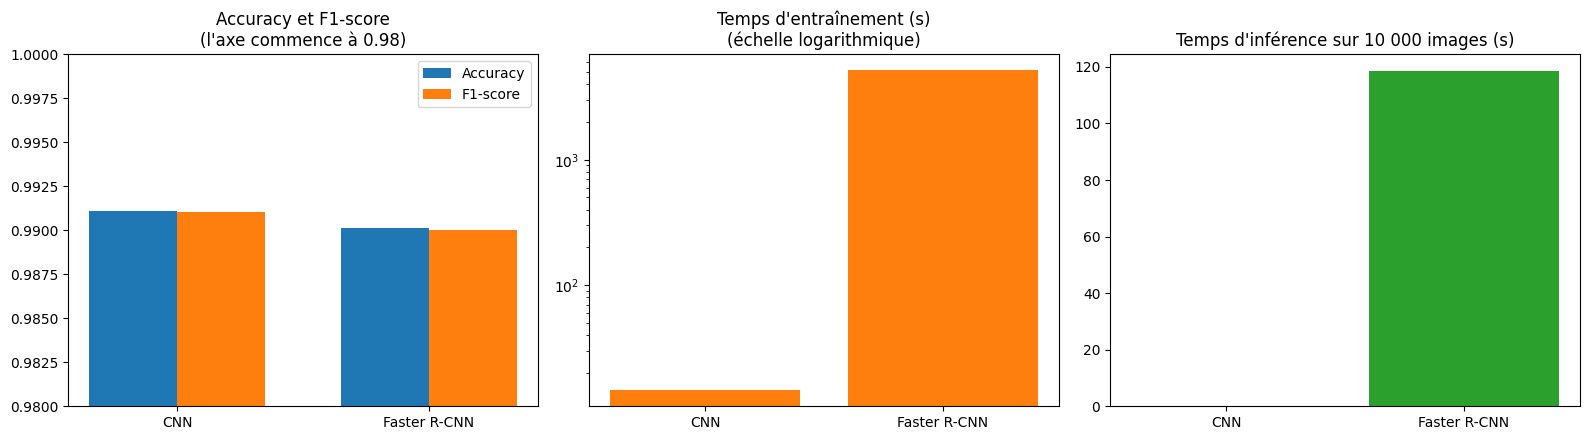

In [32]:
#On mesure le temps d'inférence du CNN sur les images de test (  car on l'a pas fait avant dans evaluation de CNN )
torch.cuda.synchronize()
debut = time.time()

# la fonction predire() qui elle passe toutes les images de test dans le modèle et renvoie les vrais chiffres et les chiffres prédits.
# On met le résultat dans "_" car on n'en a pas besoin ici , seul le temps nous interesse.
# Les predictions, on les avait déja dans l'étape 4.
_ = predire(model, testloader)

# On attend la fin des calculs du GPU, puis on arrete le chronomètre
torch.cuda.synchronize()


resultats["CNN"]["temps_inference"] = time.time() - debut

#  On compte le nombre de paramètres de chaque modèle 
resultats["CNN"]["parametres"] = sum(p.numel() for p in model.parameters())
resultats["Faster R-CNN"]["parametres"] = sum(p.numel() for p in model_rcnn.parameters())

# tableau de comparaison 
tableau = pd.DataFrame.from_dict({
    nom: {
        "Accuracy": r["accuracy"],
        "F1-score (macro)": r["f1"],
        "Loss test": r["loss"],
        "Temps d'entraînement (s)": r["temps"],
        "Temps d'inférence (s)": r.get("temps_inference"),
        "Paramètres": r.get("parametres"),
    }
    for nom, r in resultats.items() # on répete pour chaque modele du dictionnaire resultats
}, orient="index")  # orient="index" signifie que un modèle = une ligne pas une colonne

display(tableau.round(4))

# Les graphs
noms = list(tableau.index)
x = np.arange(len(noms))
largeur = 0.35

#  une figure avec 3 graphiques côte à côte.
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))


# Grap 1 : accuracy et F1 (l'axe commence à 0.98 pour voir la différence)
axes[0].bar(x - largeur/2, tableau["Accuracy"], largeur, label="Accuracy")
axes[0].bar(x + largeur/2, tableau["F1-score (macro)"], largeur, label="F1-score")
axes[0].set_ylim(0.98, 1.0)
axes[0].set_title("Accuracy et F1-score\n(l'axe commence à 0.98)")
axes[0].set_xticks(x)
axes[0].set_xticklabels(noms)
axes[0].legend()

# Graph 2 : temps de train
axes[1].bar(x, tableau["Temps d'entraînement (s)"], color="tab:orange")
# On  choisi une echellee log car  l'écart est enorme ( CNN ~15 secondes, Faster R-CNN ~5 000 secondes) => sinon, la barre du CNN serait invisible
axes[1].set_yscale("log")
axes[1].set_title("Temps d'entraînement (s)\n(échelle logarithmique)")
axes[1].set_xticks(x)
axes[1].set_xticklabels(noms)

# Graphique 3 : temps d'inférence
axes[2].bar(x, tableau["Temps d'inférence (s)"], color="tab:green")
axes[2].set_title("Temps d'inférence sur 10 000 images (s)")
axes[2].set_xticks(x)
axes[2].set_xticklabels(noms)

plt.tight_layout()
plt.show()

### Interprétation de la comparaison CNN vs Faster R-CNN

| Métrique | CNN | Faster R-CNN | Rapport |
|---|---|---|---|
| Accuracy | 0.9911 | 0.9901 | écart de 0.0010 (environ 10 erreurs de plus ) |
| F1-score (macro) | 0.9911 | 0.9900 | écart de 0.0011 |
| Loss test | 0.0266 | 0.0172 | non comparable|
| Temps d'entraînement | 14.5 s | 5 176 s (86.3 min) | plus long |
| Temps d'inférence | 0.18 s | 118.6 s |  plus long |
| Paramètres | 108 618 | 41 345 286 | environ 380 fois plus ( plus lourd)|

**Classification** : les deux modèles sont très proches, avec environ 99 % d'accuracy. Le CNN est légèrement meilleur (0.9911 contre 0.9901), soit environ 10 erreurs de moins sur les 10 000 images de test , mais cet écart reste  faible 

**Loss** : la loss de Faster R-CNN (0.0172) est plus basse que celle du CNN (0.0266), mais **cela ne veut pas dire que Faster R-CNN est meilleur**. Les deux ne mesurent pas la même chose : le CNN utilise la CrossEntropy (une seule erreur de classification), alors que Faster R-CNN additionne 4 losses (classification, boîte, et deux losses du RPN) donc on ne peut tirer aucune conclusion de cette comparaison.

**Coût de calcul** : Ici l'écart est énorme, Faster R-CNN a environ 380 fois plus de paramètres, s'entraîne environ 357 fois plus longtemps et prédit environ 670 fois plus lentement : environ 12 ms par image, contre environ 0.02 ms pour le CNN. 

**Ce que Faster R-CNN apporte en plus** : il ne se contente pas de detecter quel chiffre , il localise aussi le chiffre et pourrait en trouver plusieurs dans une même image. Le CNN ne peut pas faire cela. Mais  dans notre probleme MNIST ne demande que de la classification (un seul chiffre par image, centré), donc cette capacité n'apporte ici aucun gain de précision.

**Conclusion** : pour classer des chiffres MNIST, le CNN est le meilleur choix : il est un peu plus précis, environ 400 fois plus léger et beaucoup plus rapide. Faster R-CNN est surdimensionné pour cette tâche ; il serait justifié si l'on devait localiser plusieurs objets dans une image.

## Étape 7 : Fine-tuning de VGG16 et AlexNet

Jusqu'ici, on a construit des modèles **de zéro** :
- le **CNN**  :on a défini chaque couche Conv/Pool/FC, avec des poids initialisés au hasard ;
- le **Faster R-CNN**  : on a utilisé un backbone ResNet50 **pré-entraîné** sur ImageNet, mais la tête de détection était neuve.

maintennat on va des **modèles déjà entraînés** (VGG16 et AlexNet) et de les **fine-tuner** sur MNIST =>  **transfer learning** (apprentissage par transfert).

### Le transfer learning ?

> **Au lieu d'apprendre depuis zéro, on réutilise ce qu'un modèle a déjà appris sur une autre tâche.**

VGG16 et AlexNet ont été entraînés sur **ImageNet** ,  ils ont appris à reconnaître :
- les **bords** dans les premières couches,
- les **textures** et **motifs** dans les couches intermédiaires,
- les **formes complexes** (yeux, roues, visages) dans les couches profondes.

Ces connaissances sont **générales** : un bord reste un bord, qu'il soit sur un chat ou sur un chiffre "7". Donc ces modèles savent déjà extraire des caractéristiques utiles pour reconnaître des chiffres.

### Le fine-tuning ?

**Fine-tuner** = prendre un modèle pré-entraîné et **continuer à l'entraîner** sur nos propres données, en ajustant légèrement ses poids.

Deux stratégies existent :

| Stratégie | Ce qu'on fait | Quand l'utiliser |
|---|---|---|
| **Feature extraction** | On **gèle** toutes les couches sauf la dernière, et on entraîne seulement la nouvelle tête de classification | Quand le nouveau dataset est petit ou très différent |
| **Fine-tuning complet** | On entraîne **toutes les couches** (avec un learning rate plus petit) | Quand le dataset est assez grand ou proche d'ImageNet |

Ici, MNIST (60 000 images) est assez grand, donc on va faire  faire un **fine-tuning complet** mais avec un **learning rate plus petit** (0.0001 au lieu de 0.001), pour ne pas "écraser" les poids pré-entraînés d'un coup.



### 7.1 Préparation des données pour VGG16 / AlexNet

VGG16 et AlexNet attendent des images **224×224 en 3 canaux (RGB)**. Or MNIST fournit des images **28×28 en 1 canal (gris)**.

Il faut donc **transformer** nos images :
1. **Redimensionner** 28×28 → 224×224 (avec interpolation).
2. **Dupliquer** le canal gris 3 fois pour simuler du RGB.
3. **Normaliser** avec les moyennes/écarts-types d'ImageNet (car c'est sur ces statistiques que VGG16/AlexNet ont appris).

⚠️ **Conséquence** : les images deviennent beaucoup plus grosses l'entraînement sera **beaucoup plus lent** , et il faudra **réduire le batch size** (32 au lieu de 64) pour ne pas saturer la mémoire GPU.


In [11]:

# VGG16 et AlexNet ont été entraînés sur des images 224x224 en couleur (3 canaux)
# et normalisées avec des valeurs précises (mean/std d'ImageNet).
# Donc on  dois faire pareil pour que le modèle pré-entraîné reconnaisse bien nos images .

transform_pretrained = transforms.Compose([
    # 1 On redimensionne nos images  de 28x28 vers 224x224 
    transforms.Resize((224, 224)),
    
    # 2 Dans MNIST les images sont en gris (1 canal), mais VGG16/AlexNet attendent 3 canaux (RGB)
    #   On répète donc le canal gris 3 fois pour simuler du RGB
    transforms.Grayscale(num_output_channels=3),
    
    # 3 On convertit en tenseur  ( valeurs des pixels ramenees de [0,255] à [0,1] ) 
    transforms.ToTensor(),
    
    # 4 On normalise avec les moyennes et écarts-types d'ImageNet
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

# On recharge MNIST avec ces transformations 
train_dataset_pre = datasets.MNIST(root="./data", train=True,
                                   download=True, transform=transform_pretrained)
test_dataset_pre  = datasets.MNIST(root="./data", train=False,
                                   download=True, transform=transform_pretrained)

# --- DataLoaders ---
#  batch_size  : (32 au lieu de 64) car les images sont maintenant  plus grosses (224x224 au lieu de 28x28) -> ça prend plus de mémoire GPU
batch_size_pre = 32

trainloader_pre = DataLoader(train_dataset_pre, batch_size=batch_size_pre, shuffle=True)
testloader_pre  = DataLoader(test_dataset_pre,  batch_size=batch_size_pre, shuffle=False)

# Verification 
images_pre, labels_pre = next(iter(trainloader_pre))
print("Forme d'un batch d'images :", images_pre.shape)   # doit afficher [32, 3, 224, 224]
print("Forme d'un batch de labels :", labels_pre.shape)  # doit afficher [32]

Forme d'un batch d'images : torch.Size([32, 3, 224, 224])
Forme d'un batch de labels : torch.Size([32])


### 7.2 Fine-tuning de VGG16


#### Architecture de VGG16 

```
Entrée : image 224×224×3
│
├── Bloc 1 : [Conv 3×3, 64 filtres] × 2 + MaxPool → 112×112×64
├── Bloc 2 : [Conv 3×3, 128 filtres] × 2 + MaxPool → 56×56×128
├── Bloc 3 : [Conv 3×3, 256 filtres] × 3 + MaxPool → 28×28×256
├── Bloc 4 : [Conv 3×3, 512 filtres] × 3 + MaxPool → 14×14×512
├── Bloc 5 : [Conv 3×3, 512 filtres] × 3 + MaxPool → 7×7×512
│
├── Flatten → vecteur de 7×7×512 = 25 088 valeurs
├── FC 4096 → 4096 neurones
├── FC 4096 → 4096 neurones
└── FC 1000 → 1000 scores (les 1000 classes d'ImageNet)
```

#### ⚠️ Remarque : 
Pour une comparaison parfaitement équitable avec notre CNN et Faster R-CNN (qui ont vu les 60 000 images), il faudrait aussi utiliser les 60 000 images pour VGG16. **Mais** :
- VGG16 est **beaucoup  lourd** 
- les images font **224×224×3** au lieu de 28×28×1, soit **192 fois plus de pixels** ;
- une epoch complète sur 60 000 images prendrait **1h30 à 2h** sur le GPU Kaggle (T4 gratuit).

**Décision** : On va faire le fine-tuning sur **20 000 images**, ce qui va reduire  le temps .


#### Les sous-étapes :

| Sous-étape | Ce que on fait | Ce que on vérifie |
|---|---|---|
| **1. Chargement** | on  charge VGG16 avec ses poids ImageNet | Le modèle a bien 1000 sorties |
| **2. Remplacement de la tête** | on remplace la dernière couche FC par une nouvelle : `Linear(4096, 10)` | La sortie fait maintenant 10 scores |
| **3. Entraînement** | on  lance la boucle avec Adam (lr=0.0001), 3 epochs, sur 20 000 images | La loss baisse, l'accuracy monte |

**learning rate 0.0001  :**

Avec lr=0.001 , les gradients seraient trop grands et **écraseraient** les poids pré-entraînés dès la première epoch , cad  VGG16 oublierait tout ce qu'il a appris sur ImageNet. Avec lr=0.0001, on fait des **petites mises à jour** qui préservent les connaissances générales tout en les adaptant à MNIST.

In [12]:
# --- Import de VGG16 depuis torchvision ---
from torchvision.models import vgg16, VGG16_Weights

# Sous-étape 1 : charger VGG16 pré-entraîné sur ImageNet
vgg16_model = vgg16(weights=VGG16_Weights.IMAGENET1K_V1) # weights=VGG16_Weights.IMAGENET1K_V1 : charger les poids officiels entraînés sur ImageNet

#  Sous-étape 2 : remplacer la dernière couche FC 

# VGG16 original a 3 couches
#  Linear(25088, 4096) -> ReLU -> Dropout -> Linear(4096, 4096) -> ReLU -> Dropout ->Linear(4096, 1000) ( celle-là qu'on va remplacer avec  Linear(4096, 10) )
#   classifier[0] : Linear(25088, 4096)
#   classifier[1] : ReLU
#   classifier[2] : Dropout
#   classifier[3] : Linear(4096, 4096)
#   classifier[4] : ReLU
#   classifier[5] : Dropout
#   classifier[6] : Linear(4096, 1000)  <= On la remplace par Linear(4096, 10) pour sortir 10 chiffres.
vgg16_model.classifier[6] = nn.Linear(4096, 10)


# envoyer sur GPU 
vgg16_model = vgg16_model.to(device)

# --- Calculer le nombre de parametres total 
total_params = sum(p.numel() for p in vgg16_model.parameters())
print(f"Nombre de paramètres VGG16 : {total_params:,}")


# Sous-étape 3 : on cree  un sous-ensemble de 20 000 images ( les 20 000 premieres images de train_dataset_pre )
from torch.utils.data import Subset
indices_train = list(range(20000))
train_subset = Subset(train_dataset_pre, indices_train)

# on construit un dataloader
trainloader_vgg = DataLoader(train_subset, batch_size=32, shuffle=True)

print(f"\nNombre d'images d'entraînement utilisées : {len(train_subset)}")
print(f"Nombre de batches par epoch : {len(trainloader_vgg)}")

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:02<00:00, 235MB/s] 


Nombre de paramètres VGG16 : 134,301,514
Dernière couche : Linear(in_features=4096, out_features=10, bias=True)

Nombre d'images d'entraînement utilisées : 20000
Nombre de batches par epoch : 625


In [13]:
# la fonction d'entraînement pour VGG16 ---
# Elle reprend la meme logique de notre CNN, mais avec des hyperparams adaptés.
def entrainer_vgg(model, trainloader, testloader, epochs=3, lr=0.0001):
    
    # Loss : comme pour notre  CNN
    criterion = nn.CrossEntropyLoss()
    
    # Optimiseur : lr petit (0.0001)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    
    # on garde tj l'historique pour tracer les courbes plus tard
    historique = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}
    
   
    # torch.cuda.synchronize() : attend que le GPU ait fini ses calculs avant de démarrer le chrono.
    torch.cuda.synchronize()
    debut = time.time()

    # on a 3 epches 
    for epoch in range(epochs):
        
        # Entrainement
        model.train()   # mode train
        perte_totale, bonnes, total = 0, 0, 0
        
        for i, (images, labels) in enumerate(trainloader):
            #Envoyer  sur GPU
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad() # effacer les anciens valeurs du gradient
            sorties = model(images) # foward
            #LOss
            loss = criterion(sorties, labels)
            loss.backward() # Backward 
            # optimisation des poids
            optimizer.step()
            
            # Cumul pour calculer la moyenne de l'epoch
            perte_totale += loss.item() * images.size(0)
            bonnes += (sorties.argmax(dim=1) == labels).sum().item()
            total += images.size(0)
            
            # Affichage tous les 100 batches
            if (i + 1) % 100 == 0:
                loss_moy = perte_totale / total
                acc_moy = bonnes / total
                print(f"  Epoch {epoch+1}/{epochs} | batch {i+1}/{len(trainloader)} | "
                      f"loss moy: {loss_moy:.4f} | acc moy: {acc_moy:.4f}")
        
        # Moyennes sur l'epoch
        train_loss = perte_totale / total
        train_acc = bonnes / total
        
        # PHASE 2 : TEST 
        model.eval()   # mode évaluation (Dropout désactivé)
        perte_totale, bonnes, total = 0, 0, 0
        
        with torch.no_grad():
            for images, labels in testloader:
                images, labels = images.to(device), labels.to(device)
                sorties = model(images)
                loss = criterion(sorties, labels)
                
                perte_totale += loss.item() * images.size(0)
                bonnes += (sorties.argmax(dim=1) == labels).sum().item()
                total += images.size(0)
        
        test_loss = perte_totale / total
        test_acc = bonnes / total
        
        # Enregistrement dans l'historique
        historique["train_loss"].append(train_loss)
        historique["train_acc"].append(train_acc)
        historique["test_loss"].append(test_loss)
        historique["test_acc"].append(test_acc)
        
        # Affichage de fin d'epoch
        print(f"\n=== Epoch {epoch+1}/{epochs} terminée ===")
        print(f"  Train | loss: {train_loss:.4f} | acc: {train_acc:.4f}")
        print(f"  Test  | loss: {test_loss:.4f} | acc: {test_acc:.4f}\n")
        
        # Sauvegarde des poids après chaque epoch
        # Comme ça, si Kaggle coupe la session, on peux recharger et reprendre
        torch.save(model.state_dict(), "vgg16_mnist.pth")
        print(f"  → Poids sauvegardés dans vgg16_mnist.pth\n")
    
    # Fn de chrono
    torch.cuda.synchronize()
    temps = time.time() - debut
    print(f"Temps d'entraînement total : {temps:.1f} s ({temps/60:.1f} min)")
    
    return historique, temps


# # LANCEMENT DE L'ENTRAÎNEMENT
historique_vgg, temps_vgg = entrainer_vgg(
    model=vgg16_model,
    trainloader=trainloader_vgg,
    testloader=testloader_pre,
    epochs=3,
    lr=0.0001
)

  Epoch 1/3 | batch 100/625 | loss moy: 0.4507 | acc moy: 0.8566
  Epoch 1/3 | batch 200/625 | loss moy: 0.2716 | acc moy: 0.9155
  Epoch 1/3 | batch 300/625 | loss moy: 0.2067 | acc moy: 0.9359
  Epoch 1/3 | batch 400/625 | loss moy: 0.1771 | acc moy: 0.9459
  Epoch 1/3 | batch 500/625 | loss moy: 0.1575 | acc moy: 0.9522
  Epoch 1/3 | batch 600/625 | loss moy: 0.1443 | acc moy: 0.9569

=== Epoch 1/3 terminée ===
  Train | loss: 0.1413 | acc: 0.9579
  Test  | loss: 0.0375 | acc: 0.9888

  → Poids sauvegardés dans vgg16_mnist.pth

  Epoch 2/3 | batch 100/625 | loss moy: 0.0423 | acc moy: 0.9884
  Epoch 2/3 | batch 200/625 | loss moy: 0.0384 | acc moy: 0.9900
  Epoch 2/3 | batch 300/625 | loss moy: 0.0368 | acc moy: 0.9903
  Epoch 2/3 | batch 400/625 | loss moy: 0.0386 | acc moy: 0.9887
  Epoch 2/3 | batch 500/625 | loss moy: 0.0370 | acc moy: 0.9893
  Epoch 2/3 | batch 600/625 | loss moy: 0.0362 | acc moy: 0.9897

=== Epoch 2/3 terminée ===
  Train | loss: 0.0388 | acc: 0.9890
  Test  

#### Remarques sur l'entraînement

Pendant l'entraînement, on a remarqué un **phénomène intéressant** :

- **Epoch 1** : test acc = 98.88% (déjà très haut)
- **Epoch 2** : test acc = 97.26% (**baisse** !), et le test loss augmente
- **Epoch 3** : test acc = 98.97% (retour au sommet)

Cette fluctuation est pet etre  **normale en fine-tuning** , car  entre les epochs, le modèle modifie ses poids convolutifs pour s'adapter à MNIST, ce qui peut temporairement dégrader ses features générales.  À l'epoch 3, il l'a trouvé

### 7.3 Évaluation de VGG16

On va utilise la meme fonction `predire()` utilise pour notre  CNN. Elle fait exactement ce qu'il faut :
- passe dans le modèle en mode évaluation,
- récupère `argmax` des sorties,
- renvoie les vrais labels et les prédictions.**

In [33]:
# chronomètre pour temps d'inférence
torch.cuda.synchronize()
debut_inf = time.time()

# fonction predire 
y_vrai_vgg, y_pred_vgg = predire(vgg16_model, testloader_pre)

torch.cuda.synchronize()
temps_inf_vgg = time.time() - debut_inf

print(f"Temps d'inférence VGG16 sur 10 000 images : {temps_inf_vgg:.1f} s")

# Calcul des métriques 
acc_vgg = accuracy_score(y_vrai_vgg, y_pred_vgg)
f1_vgg = f1_score(y_vrai_vgg, y_pred_vgg, average="macro")

print(f"\nAccuracy VGG16 : {acc_vgg:.4f}")
print(f"F1-score (macro) : {f1_vgg:.4f}")
print(f"Loss test (dernière epoch) : {historique_vgg['test_loss'][-1]:.4f}")
print(f"Temps d'entraînement : {temps_vgg/60:.1f} min")

#  Rapport détaillé 
print("\n--- Rapport par chiffre ---")
print(classification_report(y_vrai_vgg, y_pred_vgg, digits=4))

# On auvegarde ca pour la comparaison finale 
resultats["VGG16"] = {
    "accuracy": acc_vgg,
    "f1": f1_vgg,
    "loss": historique_vgg["test_loss"][-1],
    "temps": temps_vgg,
    "temps_inference": temps_inf_vgg,
    "parametres": sum(p.numel() for p in vgg16_model.parameters()),
}

Temps d'inférence VGG16 sur 10 000 images : 59.8 s

Accuracy VGG16 : 0.9897
F1-score (macro) : 0.9897
Loss test (dernière epoch) : 0.0398
Temps d'entraînement : 19.4 min

--- Rapport par chiffre ---
              precision    recall  f1-score   support

           0     0.9959    0.9898    0.9928       980
           1     0.9973    0.9824    0.9898      1135
           2     0.9951    0.9845    0.9898      1032
           3     0.9921    0.9901    0.9911      1010
           4     0.9919    0.9949    0.9934       982
           5     0.9877    0.9877    0.9877       892
           6     0.9723    0.9896    0.9809       958
           7     0.9799    0.9942    0.9870      1028
           8     0.9918    0.9959    0.9939       974
           9     0.9920    0.9891    0.9906      1009

    accuracy                         0.9897     10000
   macro avg     0.9896    0.9898    0.9897     10000
weighted avg     0.9898    0.9897    0.9897     10000



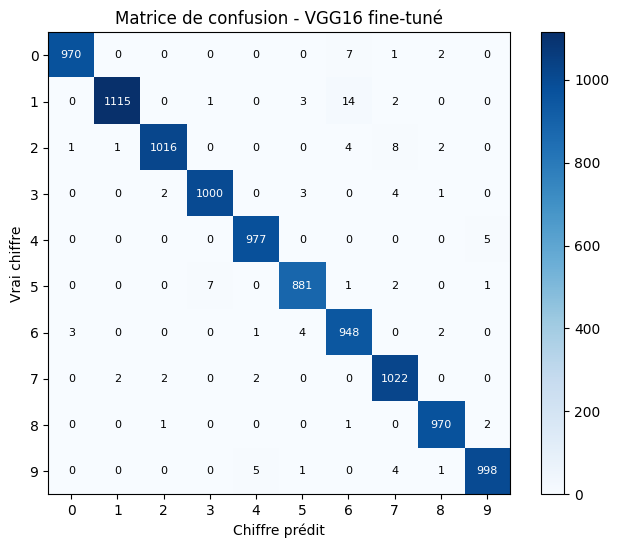

In [15]:
# --- Matrice de confusion ---
cm_vgg = confusion_matrix(y_vrai_vgg, y_pred_vgg)

plt.figure(figsize=(8, 6))
plt.imshow(cm_vgg, cmap="Blues")
plt.title("Matrice de confusion - VGG16 fine-tuné")
plt.xlabel("Chiffre prédit")
plt.ylabel("Vrai chiffre")
plt.xticks(range(10))
plt.yticks(range(10))
plt.colorbar()


for i in range(10):
    for j in range(10):
        couleur = "white" if cm_vgg[i, j] > cm_vgg.max() / 2 else "black"
        plt.text(j, i, cm_vgg[i, j], ha="center", va="center", color=couleur, fontsize=8)

plt.show()

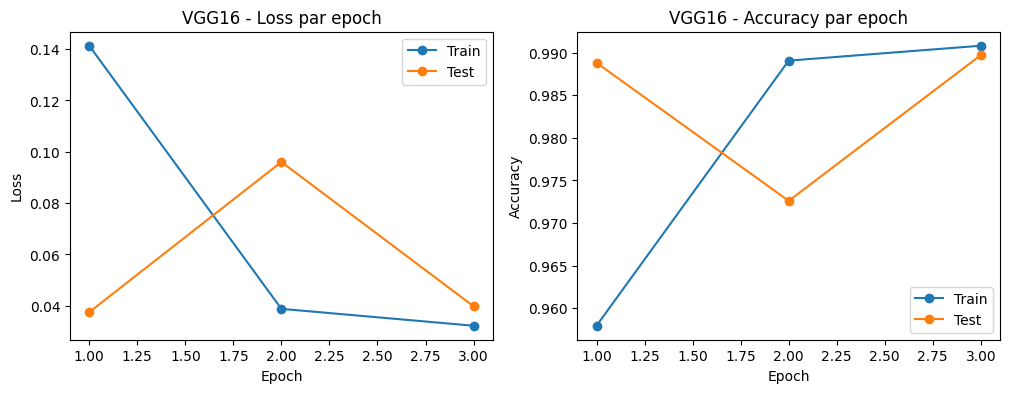

In [16]:
#  Courbes
epochs_x_vgg = range(1, len(historique_vgg["train_loss"]) + 1)

plt.figure(figsize=(12, 4))

# Courbe de la loss
plt.subplot(1, 2, 1)
plt.plot(epochs_x_vgg, historique_vgg["train_loss"], marker="o", label="Train")
plt.plot(epochs_x_vgg, historique_vgg["test_loss"], marker="o", label="Test")
plt.title("VGG16 - Loss par epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

# Courbe de l'accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs_x_vgg, historique_vgg["train_acc"], marker="o", label="Train")
plt.plot(epochs_x_vgg, historique_vgg["test_acc"], marker="o", label="Test")
plt.title("VGG16 - Accuracy par epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

### 7.4 Fine-tuning d'AlexNet

#### Architecture 
```
Entrée : image 224×224×3
│
├── Conv 11×11, 96 filtres, stride=4 → MaxPool 3×3 stride=2 → 27×27×96
├── Conv 5×5, 256 filtres, padding=2 → MaxPool 3×3 stride=2 → 13×13×256
├── Conv 3×3, 384 filtres, padding=1 → 13×13×384
├── Conv 3×3, 384 filtres, padding=1 → 13×13×384
├── Conv 3×3, 256 filtres, padding=1 → MaxPool 3×3 stride=2 → 6×6×256
│
├── Flatten → vecteur de 6×6×256 = 9216 valeurs
├── FC 4096
├── FC 4096
└── FC 1000 → 1000 scores (classes ImageNet)
```

#### Difference entre AlexNet et VGG16

AlexNet est **plus léger** que VGG16 (61M paramètres contre 138M). Il est donc plus rapide à entraîner et à évaluer, mais il est aussi **un peu moins précis** en général (moins profond, moins de capacité). Donc c'est intéressant de comparer les deux .

#### 💡 On va travailler avec la  même stratégie que pour VGG16 :


In [17]:
# Import d'AlexNet et de ses poids ImageNet 
from torchvision.models import alexnet, AlexNet_Weights

# harger AlexNet pré-entraîné ---
alexnet_model = alexnet(weights=AlexNet_Weights.IMAGENET1K_V1) # weights=VGG16_Weights.IMAGENET1K_V1 : charger les poids officiels entraînés sur ImageNet

#  Sous-étape 2 : remplacer la dernière couche FC ---
# AlexNet a 7 éléments dans son classifieur (index 0 à 6) :
#   classifier[0] : Dropout
#   classifier[1] : Linear(9216, 4096)
#   classifier[2] : ReLU
#   classifier[3] : Dropout
#   classifier[4] : Linear(4096, 4096)
#   classifier[5] : ReLU
#   classifier[6] : Linear(4096, 1000)  ← celle-là qu'on remplace par Linear(4096, 10) pour sortir 10 chiffres.
alexnet_model.classifier[6] = nn.Linear(4096, 10)

# envoyer au gPU
alexnet_model = alexnet_model.to(device)

# -voir le nombre de paramètres 
total_params_alex = sum(p.numel() for p in alexnet_model.parameters())
print(f"Nombre de paramètres AlexNet : {total_params_alex:,}")

# veriifer la  dernière couche ---
print(f"Dernière couche : {alexnet_model.classifier[6]}")

# veifier est cq que le modèle sort-il bien 10 scores 
# On passe un batch factice (2 images) pour vérifier
x_factice = torch.randn(2, 3, 224, 224).to(device)
with torch.no_grad():
    sortie_factice = alexnet_model(x_factice)
print(f"Forme de la sortie pour 2 images : {sortie_factice.shape}")


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 218MB/s]  


Nombre de paramètres AlexNet : 57,044,810
Dernière couche : Linear(in_features=4096, out_features=10, bias=True)
Forme de la sortie pour 2 images : torch.Size([2, 10])


### 7.5 Entraînement d'AlexNet

On entraine avec les mêmes hyperparamètres que pour VGG16

| Paramètre | Valeur | Pourquoi |
|---|---|---|
| Optimiseur | Adam, lr=0.0001 | Même raison : ne pas écraser les poids pré-entraînés |
| Epochs | 3 | Converge vite avec transfer learning |
| Batch size | 32 | Comme VGG16 |
| Données | 20 000 images | Même sous-ensemble pour comparer équitablement |

**Note** : ON réutilise la fonction `entrainer_vgg()` , elle porte elle prend n'importe quel modèle en argument.

In [18]:
# on réutilise la fonction entrainer_vgg() (elle marche pour n'importe quel modèle)
# on charge le même sous-ensemble de 20 000 images
historique_alex, temps_alex = entrainer_vgg(
    model=alexnet_model,
    trainloader=trainloader_vgg,   # même loader que VGG16 (20 000 images)
    testloader=testloader_pre,
    epochs=3,
    lr=0.0001
)

  Epoch 1/3 | batch 100/625 | loss moy: 0.4085 | acc moy: 0.8706
  Epoch 1/3 | batch 200/625 | loss moy: 0.2633 | acc moy: 0.9167
  Epoch 1/3 | batch 300/625 | loss moy: 0.2036 | acc moy: 0.9366
  Epoch 1/3 | batch 400/625 | loss moy: 0.1734 | acc moy: 0.9461
  Epoch 1/3 | batch 500/625 | loss moy: 0.1509 | acc moy: 0.9531
  Epoch 1/3 | batch 600/625 | loss moy: 0.1397 | acc moy: 0.9571

=== Epoch 1/3 terminée ===
  Train | loss: 0.1360 | acc: 0.9582
  Test  | loss: 0.0381 | acc: 0.9888

  → Poids sauvegardés dans vgg16_mnist.pth

  Epoch 2/3 | batch 100/625 | loss moy: 0.0464 | acc moy: 0.9847
  Epoch 2/3 | batch 200/625 | loss moy: 0.0380 | acc moy: 0.9880
  Epoch 2/3 | batch 300/625 | loss moy: 0.0410 | acc moy: 0.9873
  Epoch 2/3 | batch 400/625 | loss moy: 0.0425 | acc moy: 0.9867
  Epoch 2/3 | batch 500/625 | loss moy: 0.0445 | acc moy: 0.9866
  Epoch 2/3 | batch 600/625 | loss moy: 0.0429 | acc moy: 0.9871

=== Epoch 2/3 terminée ===
  Train | loss: 0.0441 | acc: 0.9869
  Test  

### 7.6 Évaluation d'AlexNet

Même logique que pour VGG16 :

In [34]:
# --- Prédictions ---
torch.cuda.synchronize()
debut_inf_alex = time.time()

y_vrai_alex, y_pred_alex = predire(alexnet_model, testloader_pre)

torch.cuda.synchronize()
temps_inf_alex = time.time() - debut_inf_alex

# --- Métriques ---
acc_alex = accuracy_score(y_vrai_alex, y_pred_alex)
f1_alex = f1_score(y_vrai_alex, y_pred_alex, average="macro")

print(f"Temps d'inférence AlexNet : {temps_inf_alex:.1f} s")
print(f"Accuracy AlexNet : {acc_alex:.4f}")
print(f"F1-score (macro) : {f1_alex:.4f}")
print(f"Loss test (dernière epoch) : {historique_alex['test_loss'][-1]:.4f}")
print(f"Temps d'entraînement : {temps_alex/60:.1f} min")

print("\n--- Rapport par chiffre ---")
print(classification_report(y_vrai_alex, y_pred_alex, digits=4))

# --- Sauvegarde pour comparaison finale ---
resultats["AlexNet"] = {
    "accuracy": acc_alex,
    "f1": f1_alex,
    "loss": historique_alex["test_loss"][-1],
    "temps": temps_alex,
    "temps_inference": temps_inf_alex,
    "parametres": sum(p.numel() for p in alexnet_model.parameters()),
}

Temps d'inférence AlexNet : 16.1 s
Accuracy AlexNet : 0.9909
F1-score (macro) : 0.9908
Loss test (dernière epoch) : 0.0366
Temps d'entraînement : 3.3 min

--- Rapport par chiffre ---
              precision    recall  f1-score   support

           0     0.9899    0.9959    0.9929       980
           1     0.9965    0.9956    0.9960      1135
           2     0.9884    0.9922    0.9903      1032
           3     0.9931    0.9941    0.9936      1010
           4     0.9969    0.9807    0.9887       982
           5     0.9867    0.9944    0.9905       892
           6     0.9968    0.9854    0.9911       958
           7     0.9817    0.9942    0.9879      1028
           8     0.9897    0.9897    0.9897       974
           9     0.9891    0.9861    0.9876      1009

    accuracy                         0.9909     10000
   macro avg     0.9909    0.9908    0.9908     10000
weighted avg     0.9909    0.9909    0.9909     10000



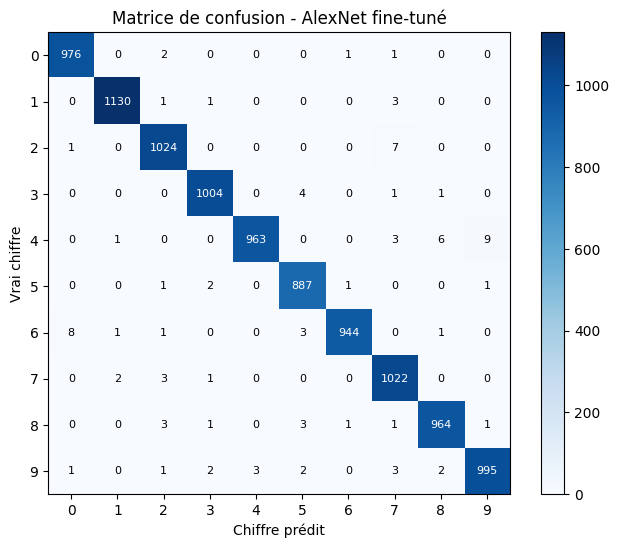

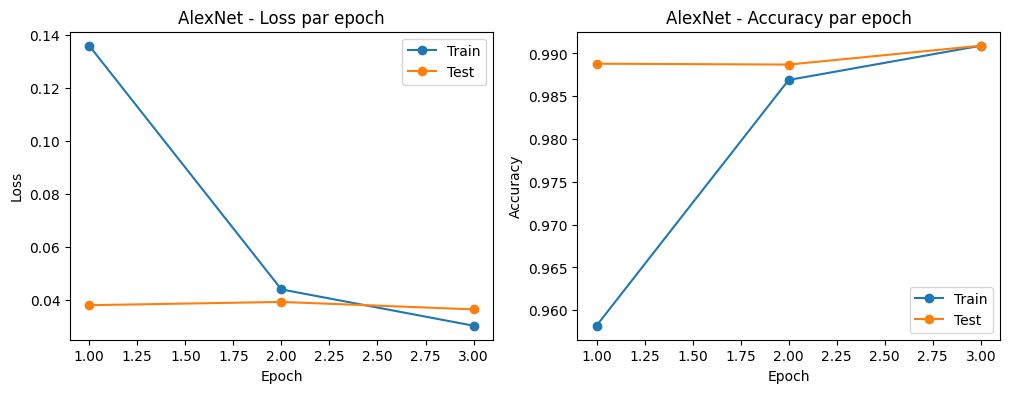

In [20]:
# --- Matrice de confusion ---
cm_alex = confusion_matrix(y_vrai_alex, y_pred_alex)

plt.figure(figsize=(8, 6))
plt.imshow(cm_alex, cmap="Blues")
plt.title("Matrice de confusion - AlexNet fine-tuné")
plt.xlabel("Chiffre prédit")
plt.ylabel("Vrai chiffre")
plt.xticks(range(10))
plt.yticks(range(10))
plt.colorbar()
for i in range(10):
    for j in range(10):
        couleur = "white" if cm_alex[i, j] > cm_alex.max() / 2 else "black"
        plt.text(j, i, cm_alex[i, j], ha="center", va="center", color=couleur, fontsize=8)
plt.show()

# --- Courbes ---
epochs_x_alex = range(1, len(historique_alex["train_loss"]) + 1)
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs_x_alex, historique_alex["train_loss"], marker="o", label="Train")
plt.plot(epochs_x_alex, historique_alex["test_loss"], marker="o", label="Test")
plt.title("AlexNet - Loss par epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_x_alex, historique_alex["train_acc"], marker="o", label="Train")
plt.plot(epochs_x_alex, historique_alex["test_acc"], marker="o", label="Test")
plt.title("AlexNet - Accuracy par epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

## Étape 8 : Comparaison finale des 4 modèles

On compare les 4 modèles sur les mêmes 10 000 images de test, selon :

- **Accuracy** : 
- **F1-score (macro)** : 
- **Temps d'entraînement** 
- **Temps d'inférence**
- **Nombre de paramètres** 


**l'équité de la comparaison** : les 4 modèles n'ont pas été entraînés dans les mêmes conditions.

| Modèle | Données | Epochs | Optimiseur |
|---|---|---|---|
| CNN | 60 000 images 28×28 | 5 | Adam |
| Faster R-CNN | 60 000 images | 3 | SGD |
| VGG16 | 20 000 images 224×224 | 3 | Adam (lr = 0.0001) |
| AlexNet | 20 000 images 224×224 | 3 | Adam (lr = 0.0001) |


In [35]:
# Tous les résultats sont dans le dictionnaire

#  tableau récapitulatif 
tableau_final = pd.DataFrame.from_dict({
    nom: {
        "Accuracy": r["accuracy"],
        "F1-score": r["f1"],
        "Temps entraînement (s)": r["temps"],
        "Temps inférence (s)": r.get("temps_inference", None),
        "Paramètres (M)": r.get("parametres", 0) / 1e6,
    }
    for nom, r in resultats.items()
}, orient="index")

# On trie par accuracy decroissante 
tableau_final = tableau_final.sort_values("Accuracy", ascending=False)

print("=== TABLEAU COMPARATIF DES 4 MODÈLES ===\n")
display(tableau_final.round(4))

=== TABLEAU COMPARATIF DES 4 MODÈLES ===



,Accuracy,F1-score,Temps entraînement (s),Temps inférence (s),Paramètres (M)
CNN,0.9911,0.9911,14.5019,0.1769,0.1086
AlexNet,0.9909,0.9908,199.1340,16.1311,57.0448
Faster R-CNN,0.9901,0.9900,5175.9017,118.5615,41.3453
VGG16,0.9897,0.9897,1166.7477,59.7633,134.3015


In [37]:
# On compte les erreurs et on compare chaque modèle au CNN (modèle de référence)
ref = tableau_final.loc["CNN"]

resume = pd.DataFrame({
    # erreurs = images mal classées sur 10 000
    "Erreurs sur 10 000": ((1 - tableau_final["Accuracy"]) * 10000).round().astype(int),
    # "x CNN" veut dire : combien de fois plus que le CNN
    "Entraînement (x CNN)": tableau_final["Temps entraînement (s)"] / ref["Temps entraînement (s)"],
    "Inférence (x CNN)": tableau_final["Temps inférence (s)"] / ref["Temps inférence (s)"],
    "Paramètres (x CNN)": tableau_final["Paramètres (M)"] / ref["Paramètres (M)"],
})
display(resume.round(1))

,Erreurs sur 10 000,Entraînement (x CNN),Inférence (x CNN),Paramètres (x CNN)
CNN,89,1.0,1.0,1.0
AlexNet,91,13.7,91.2,525.2
Faster R-CNN,99,356.9,670.2,380.6
VGG16,103,80.5,337.8,1236.5


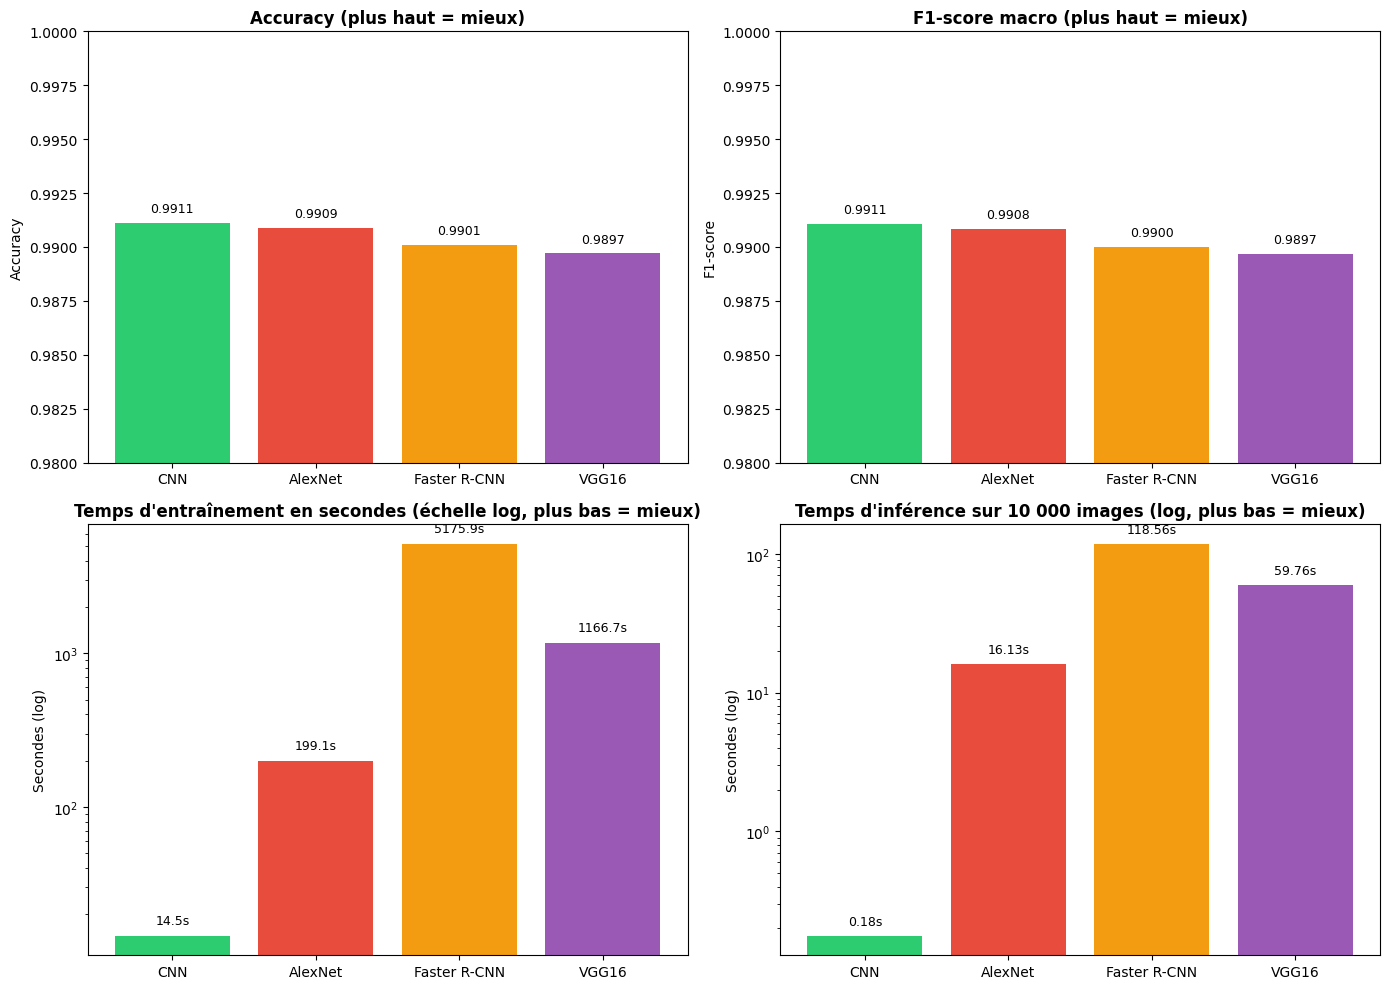

In [36]:
# --- Préparation des données pour les graphiques ---
noms_modeles = list(tableau_final.index)
couleurs = ["#2ecc71", "#e74c3c", "#f39c12", "#9b59b6"]  # vert, rouge, orange, violet

# --- Figure avec 2x2 graphiques ---
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Graphique 1 : Accuracy
axes[0, 0].bar(noms_modeles, tableau_final["Accuracy"], color=couleurs)
axes[0, 0].set_title("Accuracy (plus haut = mieux)", fontsize=12, fontweight="bold")
axes[0, 0].set_ylim(0.98, 1.0)  # on commence à 0.98 pour voir les différences
axes[0, 0].set_ylabel("Accuracy")
for i, v in enumerate(tableau_final["Accuracy"]):
    axes[0, 0].text(i, v + 0.0005, f"{v:.4f}", ha="center", fontsize=9)

# Graphique 2 : F1-score
axes[0, 1].bar(noms_modeles, tableau_final["F1-score"], color=couleurs)
axes[0, 1].set_title("F1-score macro (plus haut = mieux)", fontsize=12, fontweight="bold")
axes[0, 1].set_ylim(0.98, 1.0)
axes[0, 1].set_ylabel("F1-score")
for i, v in enumerate(tableau_final["F1-score"]):
    axes[0, 1].text(i, v + 0.0005, f"{v:.4f}", ha="center", fontsize=9)

# Graphique 3 : Temps d'entraînement (échelle log car écart énorme)
axes[1, 0].bar(noms_modeles, tableau_final["Temps entraînement (s)"], color=couleurs)
axes[1, 0].set_yscale("log")
axes[1, 0].set_title("Temps d'entraînement en secondes (échelle log, plus bas = mieux)", fontsize=12, fontweight="bold")
axes[1, 0].set_ylabel("Secondes (log)")
for i, v in enumerate(tableau_final["Temps entraînement (s)"]):
    axes[1, 0].text(i, v * 1.2, f"{v:.1f}s", ha="center", fontsize=9)

# Graphique 4 : Temps d'inférence
axes[1, 1].bar(noms_modeles, tableau_final["Temps inférence (s)"], color=couleurs)
axes[1, 1].set_yscale("log")
axes[1, 1].set_title("Temps d'inférence sur 10 000 images (log, plus bas = mieux)", fontsize=12, fontweight="bold")
axes[1, 1].set_ylabel("Secondes (log)")
for i, v in enumerate(tableau_final["Temps inférence (s)"]):
    if v is not None:
        axes[1, 1].text(i, v * 1.2, f"{v:.2f}s", ha="center", fontsize=9)

plt.tight_layout()
plt.show()

### Interprétation de la comparaison finale

| Modèle | Accuracy | F1 | Erreurs | Entraînement | Inférence | Paramètres |
|---|---|---|---|---|---|---|
| CNN | 0.9911 | 0.9911 | 89 | 14.5 s | 0.18 s | 0.11 M |
| AlexNet | 0.9909 | 0.9908 | 91 | 199.1 s | 16.1 s | 57.0 M |
| Faster R-CNN | 0.9901 | 0.9900 | 99 | 5 175.9 s | 118.6 s | 41.3 M |
| VGG16 | 0.9897 | 0.9897 | 103 | 1 166.7 s | 59.8 s | 134.3 M |

**Précision** : les 4 modèles sont extrêmement proches, entre 98.97 % et 99.11 %. Il y a seulement 14 erreurs d'écart entre le meilleur (CNN, 89 erreurs) et le moins bon (VGG16, 103 erreurs) sur 10 000 images. Une différence aussi petite peut venir du hasard (initialisation, ordre des batchs), donc on ne peut pas affirmer qu'un modèle classe réellement mieux qu'un autre. L'accuracy et le F1-score donnent le même classement, ce qui montre que les modèles sont bons sur tous les chiffres.

**Coût de calcul** : c'est ici que les modèles se distinguent vraiment.
- Le **CNN** est de loin le plus léger : 108 618 paramètres, 14.5 s d'entraînement, 0.18 s pour prédire 10 000 images.
- **AlexNet** est le meilleur compromis parmi les modèles pré-entraînés : environ 14 fois plus long à entraîner que le CNN, mais environ 6 fois plus rapide à entraîner que VGG16 (et environ 3,7 fois plus rapide pour prédire).
- **VGG16** est le plus lourd en paramètres (134 M, soit environ 1 236 fois le CNN) et n'apporte aucun gain : c'est le moins précis des 4.
- **Faster R-CNN** est le plus lent (environ 357 fois le temps d'entraînement du CNN et 670 fois son temps d'inférence), sans gain de précision.

**Ce que montre le fine-tuning** : VGG16 et AlexNet n'ont vu que 20 000 images (3 fois moins que le CNN), et pourtant ils atteignent environ 99 %. Les connaissances apprises sur ImageNet (bords, courbes, formes) se transfèrent bien aux chiffres. Mais pour un problème aussi simple que MNIST, ce transfert n'apporte pas de meilleur résultat qu'un petit CNN entraîné de zéro.

**Stabilité** : VGG16 a montré une instabilité pendant l'entraînement (l'accuracy test passe de 98.88 % à 97.26 % à l'epoch 2, puis remonte à 98.97 %), alors qu'AlexNet est resté stable (98.88 %, 98.87 %, 99.09 %).

**Limite de la comparaison** : les conditions d'entraînement ne sont pas identiques (voir le tableau plus haut : données, epochs et optimiseurs différents), et chaque modèle n'a été entraîné qu'une seule fois. Les écarts de précision doivent donc être lus comme des tendances.

**Conclusion** : pour classer des chiffres MNIST, le **CNN construit de zéro est le meilleur choix** : il a la meilleure accuracy, il est le plus petit et il est le plus rapide, avec un coût inférieur de plusieurs ordres de grandeur. AlexNet est une bonne alternative si l'on veut profiter d'un modèle pré-entraîné. VGG16 et Faster R-CNN sont surdimensionnés pour cette tâche : Faster R-CNN serait justifié pour localiser plusieurs objets dans une image, et VGG16 pour des images plus complexes que des chiffres.